## Case Técnico Data Science​
### Aplicação de Marketing Mix Modeling<br><br>
##### Tuanny Leite Almeida
##### 21/10/2026

# Case Técnico - Marketing Mix Modeling | Varejo360

## Objetivo
Estimar a contribuição incremental dos canais de mídia e seus ROIs para
apoiar decisões de alocação de orçamento.

## Estrutura da análise
1. Carregamento e qualidade dos dados
2. Escolha do target
3. Mapeamento causal das variáveis
4. EDA e riscos de identificação
5. Especificação e treinamento do MMM
6. Avaliação, contribuições e ROI
7. Limitações e próximos passos

### Configuração

In [1]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

PROJECT_ROOT = Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "varejo360_weekly.csv"

assert DATA_PATH.exists(), f"Arquivo não encontrado: {DATA_PATH}"

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

### 1. Carregamento e qualidade dos dados

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["date"])

print(f"Período: {df['date'].min():%Y-%m-%d} a {df['date'].max():%Y-%m-%d}")
print(f"Linhas: {len(df)}")
display(df.head())

Período: 2022-01-03 a 2024-12-30
Linhas: 157


,date,units_sold,revenue_brl,avg_price_brl,tv_spend_brl,google_search_spend_brl,google_display_spend_brl,meta_spend_brl,ooh_spend_brl,email_crm_sends,influencer_spend_brl,leads_generated,website_sessions,coupons_redeemed,affiliate_commission_brl,competitor_promo_index,economic_confidence_index,is_black_friday,holiday_week
0,2022-01-03,14036,4148377.54,295.55,368560.60,168914.37,43825.35,354002.48,0.00,144809,0.00,3697,21592,183,30574.28,0.0649,0.4767,0,1
1,2022-01-10,18732,5434666.79,290.13,396584.25,104078.72,55462.09,173842.47,0.00,178891,95575.06,2384,18912,267,48861.18,0.0460,0.4938,0,0
2,2022-01-17,17898,5497546.52,307.16,127587.32,166218.21,55748.43,232048.99,0.00,185146,92565.89,3089,20144,247,48270.50,0.4491,0.4964,0,0
3,2022-01-24,19195,5683675.21,296.10,188142.80,248755.49,71985.59,193572.24,0.00,160391,0.00,3445,21063,268,57632.40,0.0969,0.5891,0,0
4,2022-01-31,19781,5729271.73,289.64,120069.19,144245.76,53135.52,182615.84,222400.05,144442,0.00,2573,18913,246,69848.31,0.2387,0.5316,0,0


#### Estrutura

Aqui checamos se a estrutura da tabela está como descrita. <br>
Também tipos de dados, se as semanas são contínuas, se existem dados duplicados.<br> 
Além disso, verificamos a data de início da semana considerada.

In [3]:
#verifica colunas presentes
expected_columns = [
    "date",
    "units_sold",
    "revenue_brl",
    "avg_price_brl",
    "tv_spend_brl",
    "google_search_spend_brl",
    "google_display_spend_brl",
    "meta_spend_brl",
    "ooh_spend_brl",
    "email_crm_sends",
    "influencer_spend_brl",
    "leads_generated",
    "website_sessions",
    "coupons_redeemed",
    "affiliate_commission_brl",
    "competitor_promo_index",
    "economic_confidence_index",
    "is_black_friday",
    "holiday_week",
]

assert set(df.columns) == set(expected_columns), "Colunas diferentes do dicionário esperado."

#organiza dados cronologicamente e reseta o index
df = df.sort_values("date").reset_index(drop=True)

#cria seleção de tipo de variável
numeric_cols = df.select_dtypes(include="number").columns.tolist()
flag_cols = ["is_black_friday", "holiday_week"]

##cria panorama dos dados
print("Dimensão:", df.shape)
print("Período:", df["date"].min().date(), "a", df["date"].max().date())
print("Datas duplicadas:", df["date"].duplicated().sum())
print("Linhas totalmente duplicadas:", df.duplicated().sum())
#verifica se a semana se inicia na segunda-feira (The day of the week with Monday=0, Sunday=6)
#https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.dayofweek.html)
print("Datas em uma segunda-feira:", df["date"].dt.dayofweek.eq(0).all())
#cria lista com True se a diferença entre datas seguintes for igual a 7 dias; retorna True se todas as diferenças forem de 7 dias.
print("Semanas consecutivas:",
      df["date"].diff().dropna().eq(pd.Timedelta(days=7)).all())

Dimensão: (157, 19)
Período: 2022-01-03 a 2024-12-30
Datas duplicadas: 0
Linhas totalmente duplicadas: 0
Datas em uma segunda-feira: True
Semanas consecutivas: True


Verificamos também os tipos de dados, preenchimento, valores únicos, valores zero, mínimos e máximos.

In [4]:
quality_report = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "pct_missing": df.isna().mean().mul(100),
    "n_unique": df.nunique(),
    "min": df[numeric_cols].min(),
    "max": df[numeric_cols].max(),
    "pct_zero": df[numeric_cols].eq(0).mean().mul(100),
})

display(quality_report.round(2))

,dtype,n_missing,pct_missing,n_unique,min,max,pct_zero
affiliate_commission_brl,float64,0,0.0,157,22961.69,126848.14,0.00
avg_price_brl,float64,0,0.0,156,238.45,364.46,0.00
competitor_promo_index,float64,0,0.0,154,0.01,0.95,0.00
coupons_redeemed,int64,0,0.0,115,154.00,1633.00,0.00
date,datetime64[ns],0,0.0,157,NaN,NaN,NaN
economic_confidence_index,float64,0,0.0,145,0.43,0.95,0.00
email_crm_sends,int64,0,0.0,157,95820.00,450054.00,0.00
google_display_spend_brl,float64,0,0.0,157,21640.49,102578.04,0.00
google_search_spend_brl,float64,0,0.0,157,74129.46,396689.83,0.00
holiday_week,int64,0,0.0,2,0.00,1.00,84.71


#### Negócio

Aqui avaliamos algumas premissas de negócio.<br>
Por exemplo, dados de investimento, sessões, cupons resgatadaos e e-mails enviados devem ser valores positivos.<br>
Alguns índices devem estar dentro de uma faixa - como a variável `competitor_promo_ind
ex`, descrita no dicionário de dados como variando de 0 a 1.

In [5]:
#cria lista de variáveis não negativas e verifica se possuem apenas números positivos
non_negative_cols = [
    "units_sold",
    "revenue_brl",
    "avg_price_brl",
    "tv_spend_brl",
    "google_search_spend_brl",
    "google_display_spend_brl",
    "meta_spend_brl",
    "ooh_spend_brl",
    "email_crm_sends",
    "influencer_spend_brl",
    "leads_generated",
    "website_sessions",
    "coupons_redeemed",
    "affiliate_commission_brl",
]

for col in non_negative_cols:
    assert (df[col] >= 0).all(), f"Há valor negativo em {col}"

#verifica se flags possuem apenas valores 0 e 1 
for col in flag_cols:
    assert set(df[col].unique()).issubset({0, 1}), f"Flag inválida em {col}"

#verifica se média de pre
assert df["avg_price_brl"].gt(0).all(), "Preço médio deve ser positivo."

#verifica índice dentro do intervalo de 0 a 1
assert df["competitor_promo_index"].between(0, 1).all(), \
    "Índice de promoção de concorrente fora do intervalo esperado."

print("Validações básicas concluídas.")

Validações básicas concluídas.


#### Conclusão inicial sobre qualidade dos dados

- A base contém 157 semanas consecutivas, com granularidade semanal iniciada em segunda-feira.
- Não foram identificados valores ausentes, duplicidades ou violações das regras de negócio pré-definidas.
- Os picos mais expressivos de unidades vendidas, receita, sessões, leads e cupons coincidem visualmente com as semanas de Black Friday. Esses pontos devem ser tratados como eventos de negócio, e não como erros de qualidade.
- TV, OOH e influenciadores apresentam *flighting*: períodos concentrados de investimento intercalados com semanas sem investimento. Essa variação é útil para o MMM, mas períodos longos em zero e ativações simultâneas podem aumentar a incerteza na identificação de efeitos individuais.
- O preço médio apresenta quedas acentuadas em semanas promocionais, inclusive em Black Friday. Caso `units_sold` seja escolhido como target, preço será uma variável de contexto importante a avaliar.
- Algumas variáveis parecem variar juntas ao longo do tempo, especialmente em períodos promocionais. Nas próximas etapas, avaliaremos correlação e multicolinearidade entre mídias e controles candidatos ao modelo, para identificar dificuldades de separar seus efeitos. Lembrando, essas associações, sozinhas, não indicam uma relação causal.



### 2. Escolha do target


Observando as variáveis, nota-se que existe uma relação entre receita, unidades vendidas e preço médio.<br> 
No caso, o preço médio pode ser representado por uma razão da receita por unidades vendidas, ou <br>
`avg_price_brl` = `revenue_brl` / `units_sold` <br><br>
Para averiguar se a relação se sustenta, foi criada uma tabela com o cálculo de preço médio a partir de receita e unidades vendidas da base de dados original, chamada de `implied_avg_price`.<br> 
Tembém foi calculada a diferença absoluta (`abs_difference`) e em porcentagem (`pct_difference`) entre a nova variável e `avg_price_brl` original.

In [6]:
identity_check = df.assign(
    implied_avg_price=df["revenue_brl"] / df["units_sold"],
    abs_difference=lambda x: (
        x["implied_avg_price"] - x["avg_price_brl"]
    ).abs(),
    pct_difference=lambda x: (
        x["abs_difference"] / x["avg_price_brl"]
    ) * 100,
)

display(
    identity_check[
        [
            "date",
            "revenue_brl",
            "units_sold",
            "avg_price_brl",
            "implied_avg_price",
            "abs_difference",
            "pct_difference",
        ]
    ].head()
)

print(
    "Maior diferença absoluta entre preço observado e receita/unidades:",
    f"R$ {identity_check['abs_difference'].max():.4f}"
)

print(
    "Erro percentual máximo:",
    f"{identity_check['pct_difference'].max():.4f}%"
)

,date,revenue_brl,units_sold,avg_price_brl,implied_avg_price,abs_difference,pct_difference
0,2022-01-03,4148377.54,14036,295.55,295.552689,0.002689,0.000910
1,2022-01-10,5434666.79,18732,290.13,290.127418,0.002582,0.000890
2,2022-01-17,5497546.52,17898,307.16,307.159823,0.000177,0.000057
3,2022-01-24,5683675.21,19195,296.10,296.101860,0.001860,0.000628
4,2022-01-31,5729271.73,19781,289.64,289.635091,0.004909,0.001695


Maior diferença absoluta entre preço observado e receita/unidades: R$ 0.0050
Erro percentual máximo: 0.0017%


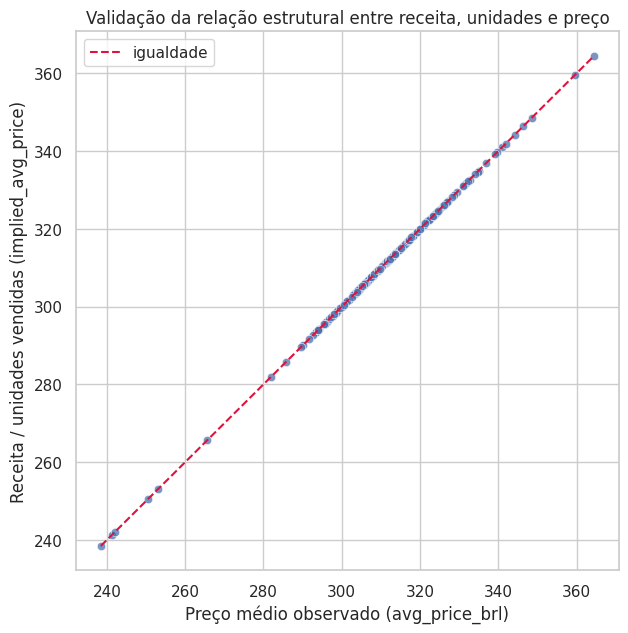

In [7]:
fig, ax = plt.subplots(figsize=(7, 7))

sns.scatterplot(
    data=identity_check,
    x="avg_price_brl",
    y="implied_avg_price",
    ax=ax,
    alpha=0.75
)

limits = [
    identity_check[["avg_price_brl", "implied_avg_price"]].min().min(),
    identity_check[["avg_price_brl", "implied_avg_price"]].max().max(),
]

ax.plot(limits, limits, linestyle="--", color="crimson", label="igualdade")
ax.set_xlabel("Preço médio observado (avg_price_brl)")
ax.set_ylabel("Receita / unidades vendidas (implied_avg_price)")
ax.set_title("Validação da relação estrutural entre receita, unidades e preço")
ax.legend()

plt.show()

Por um lado, ao escolher `revenue_brl` como variável target, o uso de `avg_price_brl` ou `units_sold` introduz um viés no modelo, uma vez que os três são relacionados, como vimos acima. Se quisermos evitar esse viés e não incluirmos essas variáveis, perdemos o fator que controla o efeito de preço - o que levaria a uma atribuição menos acurada de contribuição de cada mídia. Contudo, escolhendo essa variável, calcula-se o ROI das mídias diretamente em unidade monetária, que faz mais sentido para recomenda•ôes acionáveis.<br><br>

Quando estabelecemos `units_sold` como variável target, podemos utilizar o preço médio como fator de controle para preço sem esse viés. No entanto, essa variável traz outra implicação - ela representa uma média do preço de todos os produtos oferecidos na Varejo360, um dos maiores e-commerces de moda e acessórios do Brasil, que deve ter um catálogo amplo e variado. Esse mix pode ignorar flutuações em produtos específicos que poderiam influenciar as vendas.<br><br>

Para este estudo, vamos considerar que não ter uma forma de controlar o fator de preço comprometeria a atribuição de mídia de forma mais significativa que o trade-off do mix de produtos na média de preço. Assim, a variável target escolhida foi `units_sold`.

Com isso evitamos incluir as variáveis `avg_price_brl` e `units_sold` como componentes estruturais de `revenue_brl`, devido a nossa observação de que a receita é aproximadamente igual a unidades vendidas multiplicadas pelo preço médio realizado.

Com unidades como target, vamos então avaliar `avg_price_brl` como variável de contexto/controle para separar variações de volume associadas a preço das associadas à mídia. Entretanto, considerando o ponto do mix de produtos, a sua inclusão será avaliada por análise de sensibilidade.

Com isso, criamos uma situação - o ROI estimado não estaria em unidade monetária. Assim, uma transformação será necessária. 
O ROI será apresentado como retorno incremental estimado em receita por real investido, usando a receita observada como aproximação do valor econômico médio das unidades incrementais.

### 3. Mapeamento causal das variáveis

Como o objetivo é entendermos o papel das mídias nas vendas, precisamos estabelexer o papel de cada variável com a causalidade da venda, e identificar variáveis que possam ser influenciadas pela mídia e sequestrar sua atribuição caso consideradas.

Algumas variáveis tem papel estrutural<br>
- 'date' :  Data de início da semana (YYYY-MM-DD). Deve ordenar a série e gerar efeitos de tempo, tendência e sazonalidade.<br>
- 'units_sold' :  Unidades vendidas na semana. Selecionada como  variável target, outcome principal.<br>
- 'revenue_brl' :  Receita bruta em R$. Não entra no modelo de unidades. Serve para validar a identidade de preço e como referência econômica.<br>


Pensando em *causalidade*, podemos diferenciar as variáveis entre:

**O que causa a venda?**<br>
A variável existe antes da venda e ajuda a explicar simultaneamente a decisão de mídia e a demanda?<br><br>
Aqui entram as variáveis de investimento em mídias, do grupo `_spend`:<br>
- 'tv_spend_brl' : TV e streaming <br>
- 'google_search_spend_brl' : Buscas do Google. Geralmente atinge cliente que já busca pelo produto com maior propensão de conversão. Embora aqui isso não esteja especificado - parte desse investimento pode estar focado em busca de marca, mais genérica.<br>
- 'google_display_spend_brl' : Banners ou vídeos em sites, blogs, apps. Geralemente atinge público mais passivo, pode criar awareness. Costuma ter alcance maior. <br>
- 'meta_spend_brl' : Meta Ads, que inclui Facebook e Instagram. <br>
- 'ooh_spend_brl' : painéis, busdoor, mídia exterior <br>
- 'influencer_spend_brl' : campanhas com influenciadores <br>

Como não temos granularidade por campanha, objetivo, audiência e métricas de exposição, a interpretação de onde cada mídia age no funil fica limitada. Os efeitos que pudermos estimar vâo representar a média do mix histórico dentro de cada plataforma.<br>

Temos também variáveis que podem ser vistas como mídia orgânica, se não tivermos um investimento atrelado:<br>
- 'email_crm_sends' : Volume de e-mails enviados via CRM na semana. 
CRM pode disparar mais e-mails para clientes mais propensos a comprar ou em semanas de maior demanda.
Pode afetar diretamente o consumidor na geração de acessos ao site, geração de leads e até conversão. 
Mas pode estar superestimado - Quantos e-mails foram abertos?<br><br>


**O que pode causar a venda, mas influenciada por algum efeito de mídia?**<br>
A variável acontece no caminho entre mídia e venda?<br>

- 'affiliate_commission_brl' :  Comissão total paga ao programa de afiliados. Afiliados são pessoas ou empresas que divulgam produtos mediante pagamento de comissão. Aqui, o que foi pago é realizado após a venda, então temos uma relação direta com efeito de mídia. <br>

- 'leads_generated' : Leads capturados via formulários e landing pages.
Diretamente afetada por efeitos de mídia - O que levou a/o cliente até o formulário ou a landing page?<br>

- 'website_sessions' : Total de sessões no site na semana. Indica o tráfego, que é altamente influenciado pelo impacto das mídias.Além disso, existe critério quanto à qualidade da sessão? Pode ser um número inflado se considerar bounces, cliques acidentais.<br>

- 'coupons_redeemed' : Cupons de desconto resgatados na semana. Geralmente ofertados já no processo de compra, no carrinho, ou depois de acesso ao site. Podem trazer tráfego a mais para o site, mas esse comportamento pode ser menos comum que o anterior, e ainda dependente de mídias - por exemplo, cupons divulgado em grupos por afiliados. Ainda, existe ponderação sobre o uso dos cupons? Podem ter sido resgatados e não aplicados. <br><br>


**E o que não é mídia, mas sabemos ter papel importante na venda e precisa ter seu efeito controlado?** <br>
Aqui entram sazonalidade, eventos, preço, prazo, distribuição, concorrência, etc.:<br>
- 'is_black_friday' : Semana de Black Friday <br>
- 'holiday_week' : Semana com feriado nacional de alto impacto no varejo<br>
- 'competitor_promo_index' : Índice de intensidade promocional dos concorrentes 
Pode influenciar no tráfego e conversão, especialmente se o preço praticado no momento for competitivo - consumidor/a recebe a promoção do concorrente, pesquisa preços e acaba chegando até o produto da Varejo360.<br>
- 'economic_confidence_index' : Índice de confiança do consumidor
Pode sinalizar maior propensão de clientes para conversão de modo geral<br>

- 'avg_price_brl' :  Preço médio ponderado por unidade vendida (R$).
Isso significa a soma da receita da semana, dividida pelo número de unidades vendidas. Esse valor é calculado com base no mix de produtos ofertados pela Varejo360 - seja ele um ítem de baixo ou alto ticket. Assim, efeitos de produto, marca, categoria ficam camuflados, e isso pode ser uma limitação para o modelo. Também implica em relação de estrutura com as variáveis 'units_sold' e 'avg_price_brl', uma vez que seu cálculo deriva diretamente delas.<br>


Considerando esses pontos para selecionar as variáveis utilizadas no modelo, o ideal seria não utilizar as variáveis que sofrem influência de mídias para a venda. E avaliar a inclusão dos ocntroles de forma cautelosa, especialmente o `avg_price_br`.<br>
Desse modo, temos os grupos:

In [8]:
target = "units_sold"

paid_media = [
    "tv_spend_brl",
    "google_search_spend_brl",
    "google_display_spend_brl",
    "meta_spend_brl",
    "ooh_spend_brl",
    "influencer_spend_brl",
]

candidate_controls = [
    "avg_price_brl",
    "competitor_promo_index",
    "economic_confidence_index",
    "is_black_friday",
    "holiday_week",
]

candidate_organic_media = [
    "email_crm_sends",
]

exclude_from_mmm = [
    "revenue_brl",
    "affiliate_commission_brl",
    "leads_generated",
    "website_sessions",
    "coupons_redeemed",
]

### 4. EDA e riscos de identificação

#### Perfil Descritivo

Aqui calculamos estatísticas descritivas dos dados para entender variações, distribuição e captar alguns comportamentos como flighting

In [9]:
continuous_cols = [
    col for col in numeric_cols
    if col not in ["is_black_friday", "holiday_week"]
]

descriptive_summary = pd.DataFrame({
    "mean": df[continuous_cols].mean(),
    "median": df[continuous_cols].median(),
    "std": df[continuous_cols].std(),
    "cv": df[continuous_cols].std() / df[continuous_cols].mean(),
    "min": df[continuous_cols].min(),
    "p05": df[continuous_cols].quantile(0.05),
    "p25": df[continuous_cols].quantile(0.25),
    "p75": df[continuous_cols].quantile(0.75),
    "p95": df[continuous_cols].quantile(0.95),
    "max": df[continuous_cols].max(),
    "pct_zero": df[continuous_cols].eq(0).mean() * 100,
    "skewness": df[continuous_cols].skew(),
})

descriptive_summary["iqr"] = (
    descriptive_summary["p75"] - descriptive_summary["p25"]
)

display(descriptive_summary.round(2))

,mean,median,std,cv,min,p05,p25,p75,p95,max,pct_zero,skewness,iqr
units_sold,20436.45,19961.00,2487.04,0.12,14036.00,17439.40,18701.00,21726.00,25159.40,28233.00,0.00,0.95,3025.00
revenue_brl,6328922.39,6141852.57,742859.90,0.12,4148377.54,5441843.75,5811688.75,6675530.17,7963039.55,8704138.39,0.00,0.91,863841.42
avg_price_brl,310.43,311.12,18.89,0.06,238.45,288.88,301.78,321.15,339.38,364.46,0.00,-0.91,19.37
tv_spend_brl,129612.61,0.00,220064.29,1.70,0.00,0.00,0.00,182033.20,614265.98,1028473.84,64.97,1.69,182033.20
google_search_spend_brl,146985.38,141246.56,46272.94,0.31,74129.46,92742.38,115203.25,172608.67,216263.73,396689.83,0.00,1.70,57405.42
google_display_spend_brl,49590.79,47453.92,13209.60,0.27,21640.49,33402.83,41352.90,55600.83,72004.52,102578.04,0.00,1.13,14247.93
meta_spend_brl,231282.10,223718.36,75587.49,0.33,91533.29,136025.22,178568.16,266041.49,361390.74,657586.11,0.00,1.63,87473.33
ooh_spend_brl,144702.41,0.00,176431.88,1.22,0.00,0.00,0.00,320798.11,427579.03,563058.40,57.96,0.54,320798.11
email_crm_sends,186898.62,166750.00,69121.88,0.37,95820.00,121965.20,144442.00,199409.00,329180.00,450054.00,0.00,1.82,54967.00
influencer_spend_brl,46965.16,0.00,69470.44,1.48,0.00,0.00,0.00,101250.90,175788.80,251221.65,64.33,1.12,101250.90


In [10]:
event_summary = pd.DataFrame({
    "event_weeks": df[flag_cols].sum(),
    "pct_of_weeks": df[flag_cols].mean() * 100,
}).round(2)

display(event_summary)

,event_weeks,pct_of_weeks
is_black_friday,6,3.82
holiday_week,24,15.29


##### Perfil descritivo: principais achados

- O target apresenta variação moderada, com picos de vendas e receita que serão investigados em relação a eventos comerciais e calendário.
- O preço médio é relativamente estável, mas possui quedas concentradas, consistentes com possíveis períodos promocionais (pouco antes da Black Friday). Seu papel como controle será avaliado por análise de sensibilidade.
- TV, OOH e influenciadores possuem investimento intermitente, com mais da metade das semanas sem ativação (pct_zero entre 58% e 65%). Sua contribuição poderá apresentar maior incerteza.
- Search, Display, Meta e CRM permanecem ativos ao longo de toda a série (always on), embora Search, Meta e CRM apresentem picos de investimento ou volume.
- Cupons resgatados apresentam assimetria extrema. Na maioria das semanas, os valores são relativamente baixos, mas há poucos picos muito altos, provavelmente concentrados em ações promocionais (observando p95 e máx). De qualquer forma, já seriam excluídos do modelo por seu provável papel pós-tratamento.
- Confiança econômica será avaliada como controle candidato, considerando sua possível sobreposição com tendência temporal.

#### 1. Visão temporal do negócio

Estudar o estado da Varejo360<br>
- Quais grandes números da empresa nos últimos anos? Receita, investimento, unidades vendidas.
- Há tendência de crescimento ou queda?
- Entre as mídias, qual histórico de investimento?

Estudar relação entre demanda, preço e sazonalidade<br>
- Black Friday concentra picos de unidades, receita, preço ou todos?
- Preço e unidades se movem em direções opostas em períodos promocionais?
- Existem mudanças de patamar que o modelo precisa capturar?

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year

media_cols = [
    "tv_spend_brl",
    "google_search_spend_brl",
    "google_display_spend_brl",
    "meta_spend_brl",
    "ooh_spend_brl",
    "influencer_spend_brl",
]

df["total_media_spend_brl"] = df[media_cols].sum(axis=1)

annual = (
    df.groupby("year", as_index=False)
      .agg(
          weeks=("date", "nunique"),
          units_sold=("units_sold", "sum"),
          revenue_brl=("revenue_brl", "sum"),
          total_media_spend_brl=("total_media_spend_brl", "sum"),
      )
)

# Preço anual ponderado por unidades, preservando a identidade receita / unidades
annual["avg_price_brl"] = annual["revenue_brl"] / annual["units_sold"]

# Variação ano contra ano
for col in ["units_sold", "revenue_brl", "total_media_spend_brl", "avg_price_brl"]:
    annual[f"{col}_abs_change"] = annual[col].diff()
    annual[f"{col}_yoy_pct"] = annual[col].pct_change() * 100

annual.round(2)

,year,weeks,units_sold,revenue_brl,total_media_spend_brl,avg_price_brl,units_sold_abs_change,units_sold_yoy_pct,revenue_brl_abs_change,revenue_brl_yoy_pct,total_media_spend_brl_abs_change,total_media_spend_brl_yoy_pct,avg_price_brl_abs_change,avg_price_brl_yoy_pct
0,2022,52,1058939,3.165889e+08,39554309.34,298.97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2023,52,1076220,3.326994e+08,38373946.72,309.14,17281.0,1.63,16110576.53,5.09,-1180362.62,-2.98,10.17,3.40
2,2024,53,1073364,3.443525e+08,39686479.58,320.82,-2856.0,-0.27,11653047.16,3.50,1312532.86,3.42,11.68,3.78


In [12]:
annual_comparable = annual.copy()

for col in [
    "units_sold",
    "revenue_brl",
    "total_media_spend_brl",
]:
    annual_comparable[f"{col}_per_week"] = (
        annual_comparable[col] / annual_comparable["weeks"]
    )

for col in [
    "units_sold_per_week",
    "revenue_brl_per_week",
    "total_media_spend_brl_per_week",
    "avg_price_brl",
]:
    annual_comparable[f"{col}_yoy_pct"] = (
        annual_comparable[col].pct_change() * 100
    )

annual_comparable[[
    "year",
    "weeks",
    "units_sold_per_week",
    "revenue_brl_per_week",
    "total_media_spend_brl_per_week",
    "avg_price_brl",
    "units_sold_per_week_yoy_pct",
    "revenue_brl_per_week_yoy_pct",
    "total_media_spend_brl_per_week_yoy_pct",
    "avg_price_brl_yoy_pct",
]].round(2)

,year,weeks,units_sold_per_week,revenue_brl_per_week,total_media_spend_brl_per_week,avg_price_brl,units_sold_per_week_yoy_pct,revenue_brl_per_week_yoy_pct,total_media_spend_brl_per_week_yoy_pct,avg_price_brl_yoy_pct
0,2022,52,20364.21,6088247.53,760659.80,298.97,NaN,NaN,NaN,NaN
1,2023,52,20696.54,6398066.31,737960.51,309.14,1.63,5.09,-2.98,3.40
2,2024,53,20252.15,6497216.89,748801.50,320.82,-2.15,1.55,1.47,3.78


#### conclusões parciais da visão semanal 
Considerando a visão semanal, <br>
- Unidades semanais sobem 1,63% em 2023, mas caem 2,15% em 2024.
- Em 2024, o volume semanal fica em 20.252 unidades, 0,55% abaixo de 2022.
- A receita semanal cresce 5,09% em 2023, mas desacelera para 1,55% em 2024.
- O preço médio realizado cresce continuamente: +3,40% em 2023 e +3,78% em 2024.
- O investimento semanal cai 2,98% em 2023 e recupera apenas parcialmente em 2024; ainda fica 1,56% abaixo de 2022.<br>

Após normalizar os agregados pelo número de semanas em cada ano, observa-se estabilidade, com leve deterioração, no volume de vendas. As unidades semanais cresceram 1,6% em 2023, mas recuaram 2,2% em 2024, terminando 0,6% abaixo do patamar de 2022.<br>
A receita semanal continuou crescendo em 2024, porém em ritmo mais lento (+1,6%). Como o preço médio realizado subiu 3,8% no mesmo intervalo, o crescimento nominal de receita não corresponde a expansão de demanda em unidades; ele é compatível com aumento de preço e/ou mudança no mix de produtos vendidos.<br>
O investimento total semanal em mídia permaneceu relativamente estável, mas encerra 2024 1,6% abaixo de 2022. Essa evidência, por si só, não permite concluir que a menor venda de unidades seja causada pelo investimento em mídia: será necessário avaliar a composição dos canais, a distribuição dos investimentos ao longo do ano, eventos promocionais e carryover.

#### Distribuição de investimentos em mídias

In [13]:
media_cols = [
    "tv_spend_brl",
    "google_search_spend_brl",
    "google_display_spend_brl",
    "meta_spend_brl",
    "ooh_spend_brl",
    "influencer_spend_brl",
]

annual_media = (
    df.groupby("year")[media_cols]
      .sum()
      .T
      .reset_index()
      .rename(columns={"index": "channel"})
)

annual_media["total_2022_2024"] = annual_media[[2022, 2023, 2024]].sum(axis=1)

for year in [2022, 2023, 2024]:
    annual_media[f"share_{year}_pct"] = (
        annual_media[year] / annual_media[year].sum() * 100
    )

annual_media["change_22_24_pct"] = (
    (annual_media[2024] / annual_media[2022] - 1) * 100
)

annual_media.sort_values("total_2022_2024", ascending=False).round(2)

year,channel,2022,2023,2024,total_2022_2024,share_2022_pct,share_2023_pct,share_2024_pct,change_22_24_pct
3,meta_spend_brl,12217895.27,12291352.14,11802042.16,36311289.57,30.89,32.03,29.74,-3.40
1,google_search_spend_brl,7652417.26,7733592.30,7690694.39,23076703.95,19.35,20.15,19.38,0.50
4,ooh_spend_brl,7606007.81,7548508.93,7563762.29,22718279.03,19.23,19.67,19.06,-0.56
0,tv_spend_brl,7408532.32,5903536.91,7037109.93,20349179.16,18.73,15.38,17.73,-5.01
2,google_display_spend_brl,2615841.29,2529074.56,2640838.60,7785754.45,6.61,6.59,6.65,0.96
5,influencer_spend_brl,2053615.39,2367881.88,2952032.21,7373529.48,5.19,6.17,7.44,43.75


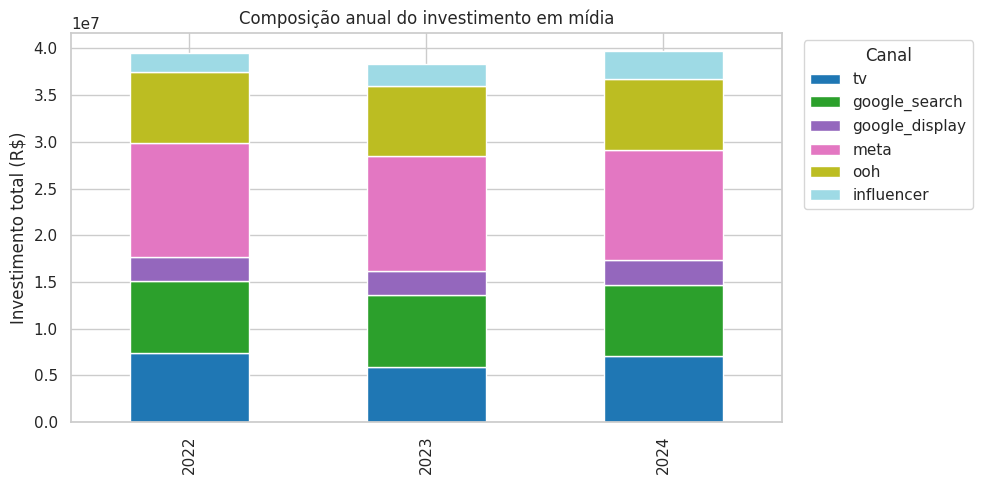

In [14]:
plot_media = (
    df.groupby("year")[media_cols]
      .sum()
      .rename(columns=lambda x: x.replace("_spend_brl", ""))
)

plot_media.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    colormap="tab20"
)

plt.title("Composição anual do investimento em mídia")
plt.xlabel("")
plt.ylabel("Investimento total (R$)")
plt.legend(title="Canal", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

- Meta é o maior componente do mix em todos os anos, perto de R$12 milhões anuais. Entre 2022 e 2024, caiu 3,4% em valor absoluto e 1,15 ponto percentual de participação no orçamento.
- TV teve a maior mudança anual de participação: caiu de 18,73% em 2022 para 15,38% em 2023, ou -3,35 pontos percentuais. Em 2024 recuperou parte do espaço, chegando a 17,73%, mas ainda com investimento 5,0% abaixo de 2022.
- Influenciadores foi a principal mudança estrutural do mix: sua participação avançou de 5,19% para 7,44% (+2,25 p.p.) e o investimento anual cresceu 43,75%. Em valor absoluto, isso equivale a cerca de R$898 mil a mais, de R$2,05M para R$2,95M.<br>

O mix de mídia é predominantemente estável. Meta, Google Search, OOH e TV representam juntos aproximadamente 86% do investimento em todos os anos; as maiores mudanças foram a redução pontual de TV em 2023 e o aumento progressivo de influenciadores. Portanto, eventuais diferenças de resultado não parecem decorrer de uma realocação ampla de orçamento entre canais, mas podem depender da distribuição temporal, dos períodos de ativação e da interação com promoções e sazonalidades.

##### Investimentos contínuos e concentrados em campanhas

In [15]:
media_profile = pd.DataFrame({
    "channel": media_cols,
    "active_weeks": [(df[col] > 0).sum() for col in media_cols],
    "pct_active_weeks": [(df[col] > 0).mean() * 100 for col in media_cols],
    "total_spend_brl": [df[col].sum() for col in media_cols],
    "mean_weekly_spend_brl": [df[col].mean() for col in media_cols],
    "mean_active_week_spend_brl": [
        df.loc[df[col] > 0, col].mean() for col in media_cols
    ],
    "max_weekly_spend_brl": [df[col].max() for col in media_cols],
    "p95_weekly_spend_brl": [df[col].quantile(0.95) for col in media_cols],
})

media_profile["max_vs_active_mean"] = (
    media_profile["max_weekly_spend_brl"]
    / media_profile["mean_active_week_spend_brl"]
)

media_profile = media_profile.sort_values(
    "total_spend_brl", ascending=False
).round(2)

media_profile

,channel,active_weeks,pct_active_weeks,total_spend_brl,mean_weekly_spend_brl,mean_active_week_spend_brl,max_weekly_spend_brl,p95_weekly_spend_brl,max_vs_active_mean
3,meta_spend_brl,157,100.00,36311289.57,231282.10,231282.10,657586.11,361390.74,2.84
1,google_search_spend_brl,157,100.00,23076703.95,146985.38,146985.38,396689.83,216263.73,2.70
4,ooh_spend_brl,66,42.04,22718279.03,144702.41,344216.35,563058.40,427579.03,1.64
0,tv_spend_brl,55,35.03,20349179.16,129612.61,369985.08,1028473.84,614265.98,2.78
2,google_display_spend_brl,157,100.00,7785754.45,49590.79,49590.79,102578.04,72004.52,2.07
5,influencer_spend_brl,56,35.67,7373529.48,46965.16,131670.17,251221.65,175788.80,1.91


- Meta, Search e Display são always-on, aparecendo ativos nas 157 semanas.
- TV, OOH e Influenciadores têm flighting, e são ativos em apenas 35% a 42% das semanas.
- TV combina poucas semanas ativas e picos fortes. A semana máxima passou de R$1 milhão, 2,8 vezes o gasto típico de uma semana ativa.
- OOH é intermitente, mas relativamente mais uniforme durante suas ativações, mostrando máximo de 1,64 vez a média ativa.
- Influenciadores também é intermitente, mas com menor variação de máximos comparados com TV.
- Os canais contínuos podem ter picos relevantes, Meta e Search têm máximos cerca de 2,7 a 2,8 vezes a média semanal cada.<br>

Meta, Search e Display operam continuamente ao longo de todo o histórico, enquanto TV, OOH e Influenciadores seguem uma estratégia de flighting, com ativações em aproximadamente 35% a 42% das semanas. <br> 
TV apresenta a maior concentração de investimento: além de ativa em apenas 35% do período, seu pico semanal é 2,8 vezes maior que o investimento típico em semanas ativas. <br>
Essa dinâmica pode dificultar a separação entre efeitos de mídia, eventos promocionais e sazonalidade, sobretudo se os voos coincidirem com Black Friday ou feriados.



##### Investigando calendário de promoções

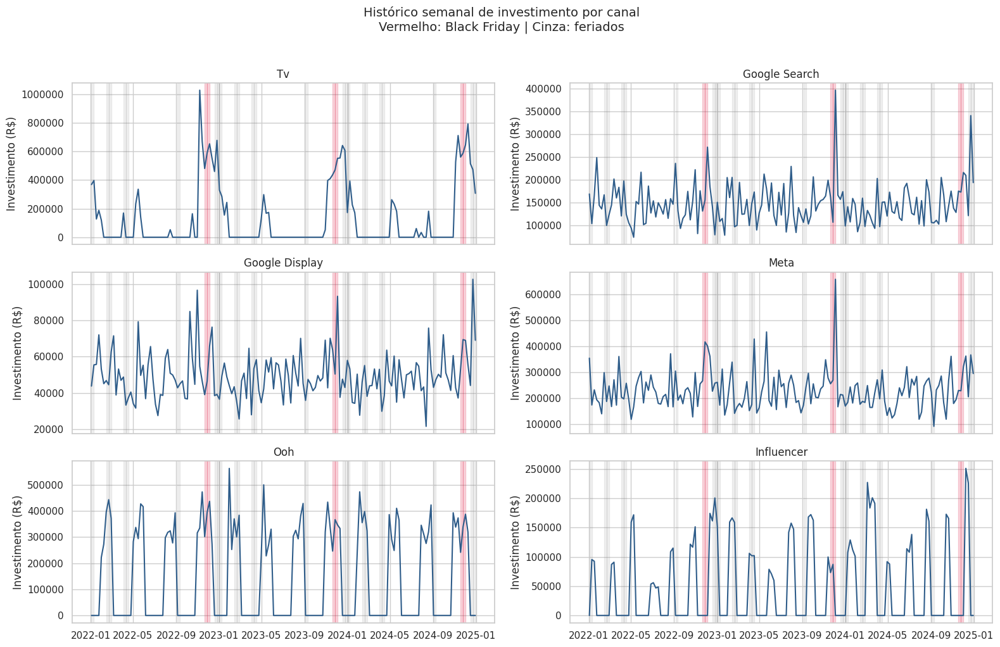

In [16]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(16, 10),
    sharex=True
)

for ax, col in zip(axes.flat, media_cols):
    ax.plot(
        df["date"],
        df[col],
        color="#2F5D8A",
        linewidth=1.5
    )

    # Feriados: faixa cinza
    for date in df.loc[df["holiday_week"] == 1, "date"]:
        ax.axvspan(
            date,
            date + pd.Timedelta(days=7),
            color="gray",
            alpha=0.12
        )

    # Black Friday: faixa vermelha
    for date in df.loc[df["is_black_friday"] == 1, "date"]:
        ax.axvspan(
            date,
            date + pd.Timedelta(days=7),
            color="crimson",
            alpha=0.18
        )

    ax.set_title(col.replace("_spend_brl", "").replace("_", " ").title())
    ax.set_ylabel("Investimento (R$)")
    ax.ticklabel_format(style="plain", axis="y")

fig.suptitle(
    "Histórico semanal de investimento por canal\n"
    "Vermelho: Black Friday | Cinza: feriados",
    y=1.02,
    fontsize=14
)

plt.tight_layout()
plt.show()

Observa-se maior intensidade conjunta de mídia em períodos de Black Friday, particularmente em canais digitais. TV, OOH e influenciadores também exibem voos relevantes fora desses eventos. A sobreposição temporal entre canais e eventos comerciais reduz a variação independente disponível para o modelo, aumentando a incerteza na atribuição de contribuição individual.

In [17]:
event_df = df.copy()

event_df["period_type"] = np.select(
    [
        event_df["is_black_friday"].eq(1),
        event_df["holiday_week"].eq(1),
    ],
    [
        "Black Friday",
        "Feriado",
    ],
    default="Semana regular"
)

event_order = ["Semana regular", "Feriado", "Black Friday"]
event_df["period_type"] = pd.Categorical(
    event_df["period_type"],
    categories=event_order,
    ordered=True
)

event_media = (
    event_df.groupby("period_type", observed=False)[media_cols]
    .agg(["mean", "median"])
    .T
)

# Deixa a leitura mais simples: médias e aumento relativo contra semanas regulares
event_mean = (
    event_df.groupby("period_type", observed=False)[media_cols]
    .mean()
    .T
)

event_mean["black_friday_vs_regular_pct"] = (
    (event_mean["Black Friday"] / event_mean["Semana regular"] - 1) * 100
)

event_mean["holiday_vs_regular_pct"] = (
    (event_mean["Feriado"] / event_mean["Semana regular"] - 1) * 100
)

event_mean.round(2)

period_type,Semana regular,Feriado,Black Friday,black_friday_vs_regular_pct,holiday_vs_regular_pct
tv_spend_brl,100847.50,183905.26,521303.37,416.92,82.36
google_search_spend_brl,146348.90,149382.32,150869.58,3.09,2.07
google_display_spend_brl,50156.85,45550.84,53768.98,7.20,-9.18
meta_spend_brl,229535.27,228919.95,277705.16,20.99,-0.27
ooh_spend_brl,146168.58,94313.05,315226.08,115.66,-35.48
influencer_spend_brl,46759.67,53103.86,26759.78,-42.77,13.57


Black Friday está particularmente associada à intensificação de TV e OOH, e em menor grau de Meta. Search e Display não exibem aumento relevante no agregado, enquanto Influenciadores têm investimento médio inferior ao das semanas regulares. Portanto, a concentração de mídia em Black Friday existe, mas é seletiva por canal, e não homogênea em todo o mix.

##### Como unidades vendidas, receita e preço médio evoluem semanalmente — e o que muda em Black Friday e feriados?

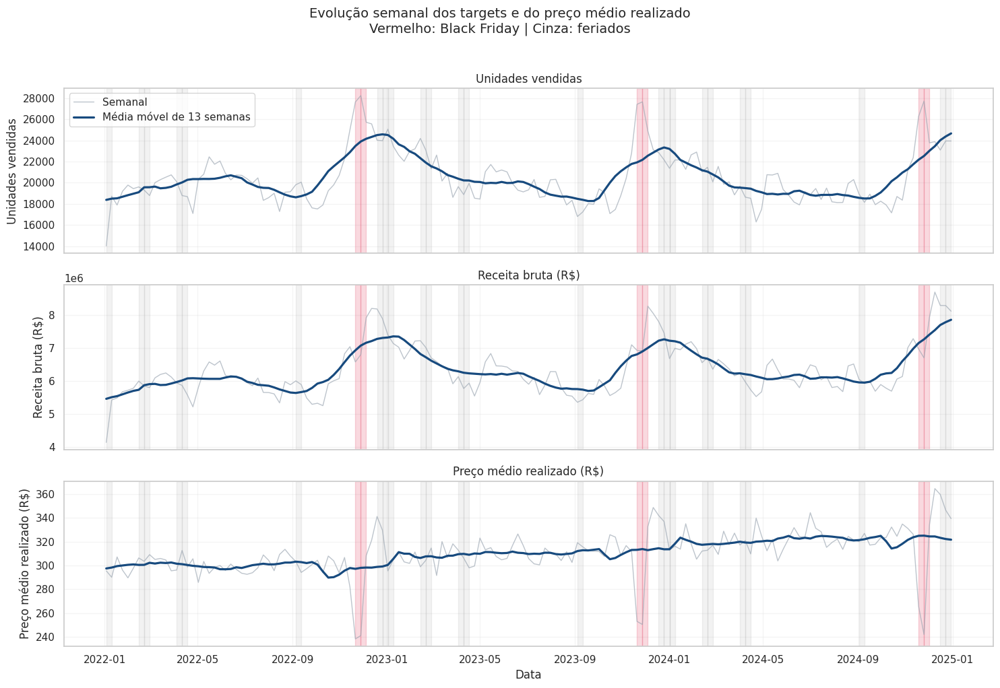

In [18]:
target_df = df.copy().sort_values("date")

target_cols = [
    ("units_sold", "Unidades vendidas"),
    ("revenue_brl", "Receita bruta (R$)"),
    ("avg_price_brl", "Preço médio realizado (R$)"),
]

#cria rolling window de 13 semanas - porque essa quantidade equivale a um quarter, considerando o ano de 52 semanas (52/4)
for col, _ in target_cols:
    target_df[f"{col}_rolling_13w"] = (
        target_df[col]
        .rolling(window=13, center=True, min_periods=1)
        .mean()
    )

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(15, 10),
    sharex=True
)

for ax, (col, label) in zip(axes, target_cols):
    ax.plot(
        target_df["date"],
        target_df[col],
        color="#9AA5B1",
        alpha=0.65,
        linewidth=1,
        label="Semanal"
    )

    ax.plot(
        target_df["date"],
        target_df[f"{col}_rolling_13w"],
        color="#174A7E",
        linewidth=2.3,
        label="Média móvel de 13 semanas"
    )

    for date in target_df.loc[target_df["holiday_week"].eq(1), "date"]:
        ax.axvspan(
            date,
            date + pd.Timedelta(days=7),
            color="gray",
            alpha=0.10
        )

    for date in target_df.loc[target_df["is_black_friday"].eq(1), "date"]:
        ax.axvspan(
            date,
            date + pd.Timedelta(days=7),
            color="crimson",
            alpha=0.16
        )

    ax.set_title(label)
    ax.set_ylabel(label)
    ax.grid(alpha=0.2)

axes[0].legend(loc="upper left")
axes[-1].set_xlabel("Data")

fig.suptitle(
    "Evolução semanal dos targets e do preço médio realizado\n"
    "Vermelho: Black Friday | Cinza: feriados",
    y=1.02,
    fontsize=14
)

plt.tight_layout()
plt.show()

Avaliando os gráficos podemos notar que existe uma sazonalidade anual bastante marcada especialmente em período de Black Friday e fim de ano, onde se observam grandes picos de unidades vendidas e receita. No entanto, para essas duas variáveis, o aumento não se sustenta, e os valores retornam aos mesmos patamares nos períodos restantes. Assim não registramos uma tendência marcada de crescimento, ou mudança de algum patamar, como já tínhamos observado anteriormente.<br>

O preço médio realizado apresenta aumento gradual ao longo da série, com quedas acentuadas durante Black Friday, o que está em linha com as promoções intensificadas do período. <br>

A coincidência de ações de desconto, aumento de unidades vendidas e de receita arrecadada se apresenta como uma maior complexidade na separação dos efeitos individuais desses fatores na modelagem.

##### quantificar a diferença entre os três tipos de semana para receita, itens vendidos e preço

In [19]:
target_event_summary = (
    event_df.groupby("period_type", observed=False)[
        ["units_sold", "revenue_brl", "avg_price_brl"]
    ]
    .agg(["mean", "median", "std"])
    .T
)

target_event_summary.round(2)

period_type           Semana regular     Feriado  Black Friday
units_sold    mean          20024.65    20853.79      27483.50
              median        19862.00    20569.50      27634.00
              std            1944.91     2657.91        652.71
revenue_brl   mean        6249343.80  6625936.45    6825279.73
              median      6099233.52  6403779.46    6868291.25
              std          670946.78  1039420.80     152973.63
avg_price_brl mean            312.13      316.91        248.52
              median          311.12      312.80        246.32
              std              13.75       17.43         10.15

De fato na Black Friday tem-se muito volume de venda, mas também grandes descontos, o que leva a um aumento de raceita, mas não proporcional ao aumento de volume.
Entre si, são semanas muito consistentes nesses quesitos, mas as observações são limitadas (apenas 6 semanas) junto com a coincidência de fatores como vimos anteriormente nos impedem de inferir causalidade.

#### Decomposição dos targets: tendência, sazonalidade e resíduos.

In [20]:
from statsmodels.tsa.seasonal import STL

stl_targets = ["units_sold", "revenue_brl"]

stl_results = {
    col: STL(
        df.set_index("date")[col],
        period=52,
        robust=False
    ).fit()
    for col in stl_targets
}

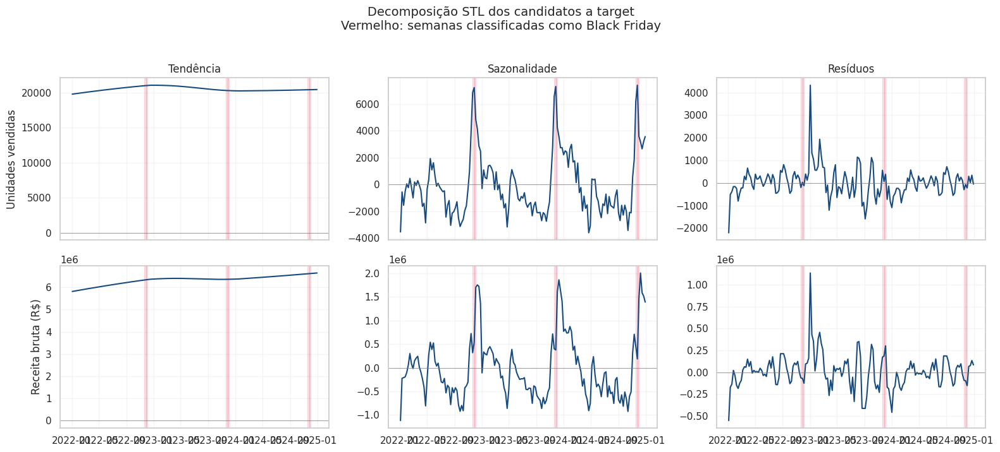

In [21]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 7),
    sharex="col"
)

components = [
    ("trend", "Tendência"),
    ("seasonal", "Sazonalidade"),
    ("resid", "Resíduos"),
]

for row, target_col in enumerate(stl_targets):
    result = stl_results[target_col]

    for col, (component, component_name) in enumerate(components):
        ax = axes[row, col]

        values = getattr(result, component)
        ax.plot(values.index, values.values, color="#174A7E", linewidth=1.5)

        for date in df.loc[df["is_black_friday"].eq(1), "date"]:
            ax.axvspan(
                date,
                date + pd.Timedelta(days=7),
                color="crimson",
                alpha=0.12
            )

        ax.axhline(0, color="gray", linewidth=0.8, alpha=0.7)
        ax.grid(alpha=0.2)

        if row == 0:
            ax.set_title(component_name)

        if col == 0:
            ax.set_ylabel(
                "Unidades vendidas"
                if target_col == "units_sold"
                else "Receita bruta (R$)"
            )

fig.suptitle(
    "Decomposição STL dos candidatos a target\n"
    "Vermelho: semanas classificadas como Black Friday",
    y=1.02,
    fontsize=14
)

plt.tight_layout()
plt.show()

In [22]:
for target_col, result in stl_results.items():
    resid = pd.Series(result.resid, index=df["date"])

    print(f"\n{target_col}")
    print(f"Proporção de resíduos aproximadamente zero: {(resid.abs() < 1e-8).mean():.1%}")
    print(resid.describe().round(2))

    reconstruction_error = (
        df[target_col].to_numpy()
        - result.trend
        - result.seasonal
        - result.resid
    )

    print(
        "Erro máximo de reconstrução:",
        np.abs(reconstruction_error).max().round(8)
    )


units_sold
Proporção de resíduos aproximadamente zero: 0.0%
count     157.00
mean       28.45
std       655.76
min     -2205.91
25%      -324.14
50%        47.21
75%       340.01
max      4321.60
Name: resid, dtype: float64
Erro máximo de reconstrução: 0.0

revenue_brl
Proporção de resíduos aproximadamente zero: 0.0%
count        157.00
mean        7481.76
std       191275.02
min      -553055.43
25%       -98333.79
50%         8130.79
75%        99005.36
max      1136109.01
Name: resid, dtype: float64
Erro máximo de reconstrução: 0.0


In [23]:
for target_col, result in stl_results.items():
    resid = np.asarray(result.resid)
    series_std = df[target_col].std()

    print(
        target_col,
        "| desvio-padrão do resíduo / desvio-padrão da série:",
        round(resid.std() / series_std, 3)
    )

units_sold | desvio-padrão do resíduo / desvio-padrão da série: 0.263
revenue_brl | desvio-padrão do resíduo / desvio-padrão da série: 0.257


Decomposição STL mais flexível, para remediar períodos de resíduo zerado. Interpretar black friday como sazonalidade, nâo como um grande outlier (robust=False)

In [24]:
stl_results = {
    col: STL(
        df.set_index("date")[col],
        period=52,
        seasonal=15,
        robust=False
    ).fit()
    for col in stl_targets
}

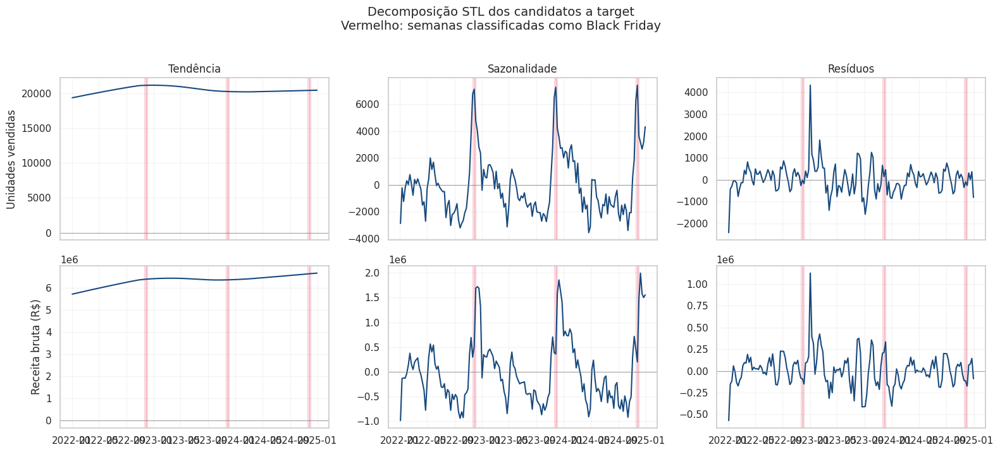

In [25]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 7),
    sharex="col"
)

components = [
    ("trend", "Tendência"),
    ("seasonal", "Sazonalidade"),
    ("resid", "Resíduos"),
]

for row, target_col in enumerate(stl_targets):
    result = stl_results[target_col]

    for col, (component, component_name) in enumerate(components):
        ax = axes[row, col]

        values = getattr(result, component)
        ax.plot(values.index, values.values, color="#174A7E", linewidth=1.5)

        for date in df.loc[df["is_black_friday"].eq(1), "date"]:
            ax.axvspan(
                date,
                date + pd.Timedelta(days=7),
                color="crimson",
                alpha=0.12
            )

        ax.axhline(0, color="gray", linewidth=0.8, alpha=0.7)
        ax.grid(alpha=0.2)

        if row == 0:
            ax.set_title(component_name)

        if col == 0:
            ax.set_ylabel(
                "Unidades vendidas"
                if target_col == "units_sold"
                else "Receita bruta (R$)"
            )

fig.suptitle(
    "Decomposição STL dos candidatos a target\n"
    "Vermelho: semanas classificadas como Black Friday",
    y=1.02,
    fontsize=14
)

plt.tight_layout()
plt.show()

A decomposição STL foi realizada considerando um ciclo anual de 52 semanas. Inicialmente, a configuração mais flexível fazia com que grande parte dos resíduos ficasse próxima de zero, indicando que a sazonalidade poderia estar absorvendo variações específicas demais. Por isso, foi utilizada uma suavização sazonal de 13 períodos, buscando manter os padrões recorrentes sem ajustar cada oscilação semanal como sazonalidade.
Para units_sold, não se observa uma tendência persistente de crescimento ou queda. Há algumas variações graduais de nível ao longo da série, mas o comportamento geral se mantém relativamente estável.
Já revenue_brl apresenta uma leve tendência de aumento, coerente com o crescimento do preço médio realizado observado anteriormente. Nas duas séries, há uma sazonalidade anual marcada, com picos recorrentes próximos à Black Friday. Esse efeito parece mais diretamente alinhado às unidades vendidas; em receita, ele aparenta ser mais amplo ou levemente deslocado, possivelmente pela combinação entre aumento de volume e descontos.
Com a nova configuração, os resíduos passam a oscilar em torno de zero ao longo de toda a série. Ainda existem desvios pontuais, especialmente no início de 2023 e no começo do histórico, mas não há evidência visual de uma quebra estrutural prolongada.
Essa análise é exploratória e não será usada diretamente como variável no MMM. Ela reforça, no entanto, a necessidade de considerar sazonalidade e Black Friday na modelagem.

#### Correlação e multicolinearidade entre mídias e controles candidatos.

In [26]:
organic_media_candidates = [
    "email_crm_sends",
]

control_candidates = [
    "avg_price_brl",
    "competitor_promo_index",
    "economic_confidence_index",
    "is_black_friday",
    "holiday_week",
]

candidate_explanatory_cols = (
    paid_media
    + organic_media_candidates
    + control_candidates
)

corr_pearson = df[candidate_explanatory_cols].corr(method="pearson")
corr_spearman = df[candidate_explanatory_cols].corr(method="spearman")

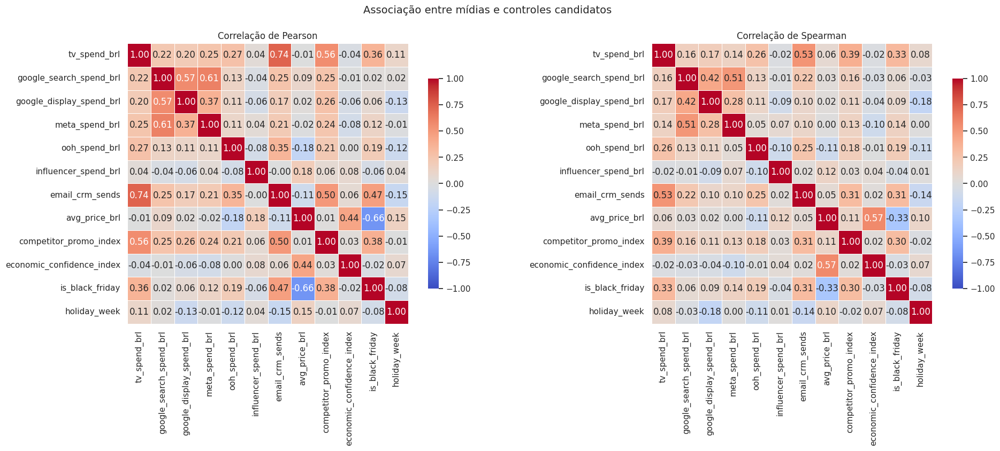

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

for ax, corr, title in zip(
    axes,
    [corr_pearson, corr_spearman],
    ["Correlação de Pearson", "Correlação de Spearman"]
):
    sns.heatmap(
        corr,
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        annot=True,
        fmt=".2f",
        square=True,
        linewidths=0.5,
        cbar_kws={"shrink": 0.75},
        ax=ax
    )
    ax.set_title(title)

plt.suptitle(
    "Associação entre mídias e controles candidatos",
    y=1.02,
    fontsize=14
)

plt.tight_layout()
plt.show()

In [28]:
def correlation_pairs(corr_matrix, method_name):
    mask = np.triu(
        np.ones(corr_matrix.shape, dtype=bool),
        k=1
    )

    return (
        corr_matrix
        .where(mask)
        .stack()
        .rename(method_name)
        .reset_index()
        .rename(columns={
            "level_0": "variable_1",
            "level_1": "variable_2"
        })
    )

pearson_pairs = correlation_pairs(corr_pearson, "pearson")
spearman_pairs = correlation_pairs(corr_spearman, "spearman")

top_correlations = (
    pearson_pairs
    .merge(
        spearman_pairs,
        on=["variable_1", "variable_2"]
    )
    .assign(
        max_abs_correlation=lambda x: x[["pearson", "spearman"]]
        .abs()
        .max(axis=1)
    )
    .sort_values("max_abs_correlation", ascending=False)
)

top_correlations.head(10).round(2)

,variable_1,variable_2,pearson,spearman,max_abs_correlation
5,tv_spend_brl,email_crm_sends,0.74,0.53,0.74
58,avg_price_brl,is_black_friday,-0.66,-0.33,0.66
12,google_search_spend_brl,meta_spend_brl,0.61,0.51,0.61
57,avg_price_brl,economic_confidence_index,0.44,0.57,0.57
11,google_search_spend_brl,google_display_spend_brl,0.57,0.42,0.57
7,tv_spend_brl,competitor_promo_index,0.56,0.39,0.56
52,email_crm_sends,competitor_promo_index,0.50,0.31,0.50
54,email_crm_sends,is_black_friday,0.47,0.31,0.47
61,competitor_promo_index,is_black_friday,0.38,0.30,0.38
21,google_display_spend_brl,meta_spend_brl,0.37,0.28,0.37


Os principais pares são:
- TV × CRM: 0,74 Pearson; 0,53 Spearman.
- Search × Meta: 0,61; 0,51.
- Search × Display: 0,57; 0,42.
- Black Friday × preço médio: -0,66; -0,33.
- Preço médio × confiança econômica: 0,44; 0,57.
- TV × promoção do concorrente: 0,56; 0,39.
- CRM × promoção do concorrente: 0,50; 0,31.

Há diferenças relevantes entre Pearson e Spearman em alguns pares. A principal é avg_price_brl × Black Friday: -0,66 em Pearson e -0,33 em Spearman. Isso sugere que a relação linear em Pearson é muito influenciada pelas quedas intensas de preço nas semanas promocionais.<br>

Não há correlações extremas entre os canais pagos que indiquem redundância completa de informação. Ainda assim, TV e CRM, Search e Meta, e Search e Display apresentam associação moderada, o que pode aumentar a incerteza ao separar seus efeitos no MMM. Black Friday tem associação negativa relevante com preço médio, coerente com períodos promocionais. Essas relações serão investigadas também com VIF; elas não implicam exclusão automática de variáveis nem estabelecem causalidade.

##### Outliers

Para calcular os outliers, consideramos os resíduos dos targets. <br>
Assim conseguimos avaliar as semanas que foram incomuns mesmo depois de considerar tendência e sazonalidade, e não tratamos automaticamente uma Black Friday como anomalia; <br>
Ao invés de z-score usamos robust z-score, que é menos afetado por picos extremos.

In [29]:
#Robust z-score sinaliza semanas incomuns sem ser dominado por picos extremos, como os efeitos de sazonalidade da Black Friday.
#O limiar é apenas para investigação, não necessariamente implicando em remoção do dado.
OUTLIER_Z_THRESHOLD = 3.5
TARGETS_TO_DIAGNOSE = ["units_sold", "revenue_brl"]


def robust_zscore(series):
    """Calcula z-score robusto a partir da mediana e do MAD."""
    median = series.median()
    #MAD é o desvio absoluto mediano em torno da mediana. 
    mad = (series - median).abs().median()

    if pd.isna(mad) or np.isclose(mad, 0):
        raise ValueError(
            "MAD nulo ou inválido. Revise a decomposição STL antes de interpretar outliers."
        )
    #Em uma normal, o valor de MAD é aproximadamente 0,6745 × desvio-padrão, então por isso usamos 0.6745 para escalar o robust z-score.
    return 0.6745 * (series - median) / mad


#Mantemos o índice posicional para alinhar corretamente os resíduos da STL.
context_cols = [
    "date",
    "units_sold",
    "revenue_brl",
    "avg_price_brl",
    "total_media_spend_brl",
    "is_black_friday",
    "holiday_week",
]
outlier_df = df[context_cols].copy()

for target_col in TARGETS_TO_DIAGNOSE:
    residuals = pd.Series(
        np.asarray(stl_results[target_col].resid),
        index=outlier_df.index,
        name=f"{target_col}_resid",
    )

    if residuals.isna().any():
        raise ValueError(f"Há resíduos nulos para {target_col}.")

    outlier_df[f"{target_col}_resid"] = residuals
    outlier_df[f"{target_col}_robust_z"] = robust_zscore(residuals)

outlier_df["is_target_outlier"] = (
    outlier_df["units_sold_robust_z"].abs().gt(OUTLIER_Z_THRESHOLD)
    | outlier_df["revenue_brl_robust_z"].abs().gt(OUTLIER_Z_THRESHOLD)
)

outlier_summary = pd.DataFrame(
    {
        "n_outliers": [
            outlier_df["units_sold_robust_z"].abs().gt(OUTLIER_Z_THRESHOLD).sum(),
            outlier_df["revenue_brl_robust_z"].abs().gt(OUTLIER_Z_THRESHOLD).sum(),
        ],
        "max_abs_robust_z": [
            outlier_df["units_sold_robust_z"].abs().max(),
            outlier_df["revenue_brl_robust_z"].abs().max(),
        ],
    },
    index=TARGETS_TO_DIAGNOSE,
)

target_outliers = (
    outlier_df.loc[
        outlier_df["is_target_outlier"],
        [
            "date",
            "units_sold",
            "revenue_brl",
            "avg_price_brl",
            "total_media_spend_brl",
            "is_black_friday",
            "holiday_week",
            "units_sold_robust_z",
            "revenue_brl_robust_z",
        ],
    ]
    .sort_values("date")
)

print("Diagnóstico de outliers nos resíduos STL")
display(outlier_summary.round(2))
print(f"Limiar de investigação: |robust z-score| > {OUTLIER_Z_THRESHOLD}")
display(target_outliers.round(2))


Diagnóstico de outliers nos resíduos STL


,n_outliers,max_abs_robust_z
units_sold,2,7.87
revenue_brl,1,6.60


Limiar de investigação: |robust z-score| > 3.5


,date,units_sold,revenue_brl,avg_price_brl,total_media_spend_brl,is_black_friday,holiday_week,units_sold_robust_z,revenue_brl_robust_z
0,2022-01-03,14036,4148377.54,295.55,935302.80,0,1,-4.44,-3.44
52,2023-01-02,25059,7405241.75,295.51,930339.44,0,1,7.87,6.60


A análise dos resíduos identificou duas semanas como outliers para unidades vendidas e uma para receita.
Ambas ocorrem no início de janeiro e estão classificadas como feriado.  <br>
A primeira observação da série, em 2022-01-03, deve ser interpretada com cautela por não haver histórico anterior para representar tendências ou possíveis efeitos acumulados de mídia, ou seja, seu cálculo de resíduo é menos informativo. <br>
Já 2023-01-02 apresenta resultado acima do esperado e investimento elevado, o que pode sugerir que alguma dinâmica de virada de ano não foi capturada pelos controles. <br>
Como não temos evidência de erro de qualidade as semanas serão mantidas no conjunto de dados, e sua influência será acompanhada nos diagnósticos do modelo.

### RESUMO DA EDA|

| Risco identificado | Evidência na EDA | Como será tratado |
|---|---|---|
| Sobreposição entre mídia e Black Friday | TV e OOH estão ativas em todas as semanas de Black Friday; Meta também aumenta no período | Incluir Black Friday como controle e interpretar os ROIs desses canais junto com seus intervalos de incerteza |
| Preço, promoção e mix | Em Black Friday, unidades sobem enquanto preço médio cai; receita mistura volume e ticket | Usar `units_sold` como target principal; testar `avg_price_brl` como controle e comparar com uma versão sem preço |
| *Flighting* | TV, OOH e Influenciadores têm longos períodos sem investimento | Manter os canais, mas reconhecer que estimativas podem ter maior incerteza por haver menos variação disponível |
| CRM e variáveis de funil | CRM se move junto de outros canais; sessões, leads, cupons e comissão podem ser consequência da mídia ou da venda | Avaliar CRM separadamente como canal orgânico; excluir sessões, leads, cupons e comissão do modelo principal |
| Eventos heterogêneos | A flag de feriado agrupa eventos diferentes; janeiro de 2023 permanece como semana atípica | Usar a flag disponível como controle, mas registrar que ela não representa todos os efeitos específicos de calendário |
| Histórico limitado | Há apenas três ciclos anuais e não há dados anteriores a janeiro de 2022 | Usar uma especificação parsimoniosa, monitorar efeito de borda e evitar conclusões excessivamente precisas |
| Base nacional agregada | Não há variação geográfica para criar grupos de comparação | Tratar os resultados como estimativas condicionais às hipóteses do MMM; recomendar testes de incrementalidade para calibração futura |

## 5. Modelagem: seleção de especificação

Levando em consideração toda discussão até aqui, estabelecemos alguns critérios para a modelagem:

- As variáveis consideradas influenciadas por mídia para ocasionar a venda nâo serão inclusas;
- As variáveis de confiança econômica e preço médio serão testadas como controles;
- Os modelos serão treinados com o conjunto de dados limitado ao período das primeiras 131 semanas, enquanto as últimas 26 servem como conjunto de validação para comparação dos desempenhos;
- Partiremos das configurações mais simples, e se necessário serão feitos ajustes;
- Partiremos do conjunto de dados mais simples (sem os dois controles em investigação) para o mais complexo (com a adição de ambos controles)

Nossa hipótese é de que, mesmo com o trade-off do mix de produtos, o modelo com a variável de preço médio pode oferecer uma melhor estimativa da contribuição das mídias.

Faremos então alguns testes com draws reduzidos para averiguar quais modelos tem mais potencial, e um dos modelos eleito será treinado no conjunto de dados completo para informar uma recomendação ao CMO.

Idealmente teremos as versões:
- M00: Modelo base (Todas as variáveis de mídia, mais controles base 'competitor_promo_index', 'is_black_friday', 'holiday_week',)
- M01: Modelo base + 'economic_confidence_index'
- MO2: Modelo base + 'avg_price_brl'
- M03: Modelo base + 'economic_confidence_index' + 'avg_price_brl'

Foram criadas funções para que a execução dos modelos fique mais flúida e rastreável, e as variáveis ficam definidas em seguida para apoiá-las.

### Análise e resultados

Testamos as versẽs do modelo propostas, com uma adição no caminho. De forma resumida como resultado temos:

- **M00: Modelo base**
Performou boas métricas de holdout (R2 = 0.94 e wMAPE = 2,74%) e boa convergência em rhat. TV se apresentou o canal mais estável, enquanto os demais mostram uma maior faixa de incerteza nos valores estimados de ROI, saturação e Adstock. 
Aqui notamos que o efito de Adstock para TV ainda era alto ao final do período de 8 semanas - cerca de 65%. Assim, adicionamos um teste de período de memória estendido para 12 semanas (lag = 12). Foi inserido como próximo modelo teste, o MLag12
- **MLag12: Modelo base com lag = 12**
Performou métricas ligeiramente melhores melhores R2, MAPE, wMAPE em relação a M00. O melhor estimador de toda série, com R2 = 0.95, MAPE = 2,47%, wMAPE 2,47% e Rhat = 1,020. E principalmente, foi possível melhor o perfil de decaimento de TV sem modificar os perfis das outras mídias. Assim optamos por manter esse ajuste para os próximos testes.
- **M01: MLag12 + 'economic_confidence_index'
Para este teste, vimos uma ligeira piora nos valores de holdout e convergência do modelo em relação a MLag12, e sem ganhos em redução das incertezas de estimativas de ROI, então a adição de 'economic_confidence_index' de forma isolada como controle foi despriorizada.
- **MO2: MLag12 + 'avg_price_brl'**
Neste teste, temos virtualmente o mesmo resultado em relação a MLag12, fechando em R2 = 0.95, MAPE = 2,51%, wMAPE 2,55% e Rhat = 1,009. 
No entanto notamos mudanças relevantes nas atribuiçoes de ROI para os canais de mídia. Search e Influencer continuam com os maiores ROIs estimados, e TV continua com o ROI mais estável entre modelos e com incerteza baixa. Os valores de Meta e Display não mudam de patamar, e eles seguem com grande incerteza. Mas OOH tem seu valor de ROI praticamente dobrado - 1,54 para 3,03 - mas sem diminuir a incerteza do canal.
O padrão de adstock de OOH também mudou significativamente, o que pode ter contribuíodo para a alteração no valor do ROI - seu efeito se estende por mais tempo.
Aqui notamos que existe uma mudança de ordem de contribuição das mídias também, que pode refletir em uma recomendação de otimização.

- **M03: MLag12 + 'economic_confidence_index' + 'avg_price_brl'**
O o modelo com os dois controles piorou no holdout dm relação a MLag12 e M02. A piora é pequena mas consistente entre as métricas e o R-hat máximo de 1,035 é o mais alto entre os modelos testados. 
Adicionar confiança econômica depois do preço reduziu um pouco alguns ROIs, mas não reslolveu a incerteza dos canais mais frágeis. Assim não temos evidência de melhora suficiente para mantê-la.

Temos como melhores candidatos os modelos MLag12 e M02.
Os modelos convergem sobre as estimatimativas dos maiores ROIs, das incertezas dos canais de mídia. 
O ponto de dissonância entre eles é a estimativa do ROI de OOH, que quase dobra no modelo com preço como controle, mas mantendo sua incerteza. Com isso pode-se inferir que essa mídia é muito sensível ao efeito do controle de preço, e independente do modelo selecionado, a recomendação para ajuste dessa mídia deve ser muito comedida.
Uma hipótese pode ser a ativação mais forte dessa mídia juntamente com outras mídias e promoções, uma vez que exibe um padrão de flighting em seus investimentos.

Retomando a pergunta do cliente:
“Qual é a contribuição causal de cada canal de mídia nas vendas, e qual é o ROI para orientar orçamento?”

O interesse principal é o efeito total da mídia sobre unidades vendidas. 
Como estamos assumindo a premissa de que avg_price_brl é o preço médio realizado na semana, de acordo com a análise das variáveia mais acima, temos que considerar que este não é um controle causal ideal.
Em moda e acessórios, mídia pode afetar mix vendido, participação de produtos em promoção e composição de marcas, afetando diretanente a variável `avg_price_br`.
Uma vez que a adição do controle tenha causado uma mudança de patamar no modelo base estabelecido, acreditamos que sua adição possa estar trazendo algum efeito que não pode ser isolado, e de mais difícil separaçao.
No entanto, no modelo com o preço médio como controle temos o aumento do ROI geral e diminuição de incertezas para canais como Display, Meta e TV.

Assim seguimos com o modelo MLag12, sem a adição do controle de preço.e podemos sugerir a inclusão de alguma feature relacioana ao preço, mas que tenha menor viés pós venda para uma nova iteração do modelo.

O modelo selecionado foi reestimado com as 157 semanas disponíveis. Esta etapa busca utilizar toda a informação histórica para gerar as atribuições e recomendações de orçamento.

#### Separação temporal para validação

Para comparar as primeiras especificações do MMM, as últimas 26 semanas serão reservadas como *holdout* de validação temporal. O período de treino contém 131 semanas, contemplando mais de dois ciclos anuais completos.

A validação fica após o treino, respeitando a ordem natural da série. Ela inclui semanas de alta variação, como Black Friday, pois o objetivo é avaliar se o modelo consegue representar períodos futuros relevantes para o planejamento de mídia, considerando calendário, controles e investimentos observados.

Essa será a validação principal da primeira rodada. Após termos uma especificação funcional, a robustez poderá ser investigada com validação de janela expansiva.

In [30]:
VALIDATION_WEEKS = 26

model_df = (
    df
    .sort_values("date")
    .reset_index(drop=True)
    .copy()
)

#Remove do conjunto de dados a quantidade de semanas especificadas como validação em `VALIDATION_WEEKS`
validation_start = model_df.loc[
    len(model_df) - VALIDATION_WEEKS,
    "date"
]

#cria coluna com status de grupo entre "train" e "validation"
model_df["sample"] = np.where(
    model_df["date"] < validation_start,
    "train",
    "validation",
)

#filtra dataset de treino pela sample = "train"
train_df = model_df.loc[
    model_df["sample"].eq("train")
].copy()

#filtra dataset de validação pela sample = "validation"
validation_df = model_df.loc[
    model_df["sample"].eq("validation")
].copy()

assert len(validation_df) == VALIDATION_WEEKS
assert train_df["date"].max() < validation_df["date"].min()

split_summary = (
    model_df.groupby("sample", observed=False)
    .agg(
        start_date=("date", "min"),
        end_date=("date", "max"),
        weeks=("date", "size"),
        black_friday_weeks=("is_black_friday", "sum"),
        holiday_weeks=("holiday_week", "sum"),
    )
    .reindex(["train", "validation"])
)

display(split_summary)

,start_date,end_date,weeks,black_friday_weeks,holiday_weeks
sample,,,,,
train,2022-01-03,2024-07-01,131,4,21
validation,2024-07-08,2024-12-30,26,2,3


In [31]:
from pathlib import Path

import numpy as np
import pandas as pd

from meridian.analysis import analyzer, summarizer, visualizer
from meridian.data.data_frame_input_data_builder import DataFrameInputDataBuilder
from meridian.model import model, spec

REPORT_DIR = Path('outputs/model_reports')

SELECTION_SAMPLING = {
    "n_chains": 4,
    "n_adapt": 500,
    "n_burnin": 250,
    "n_keep": 400,
    "seed": 42,
}

FINAL_SAMPLING = {
    "n_chains": 4,
    "n_adapt": 800,
    "n_burnin": 400,
    "n_keep": 800,
    "seed": 42,
}

MEDIA_COLS = [
    'tv_spend_brl',
    'google_search_spend_brl',
    'google_display_spend_brl',
    'meta_spend_brl',
    'ooh_spend_brl',
    'influencer_spend_brl',
]

MEDIA_CHANNELS = [
    'TV',
    'Google Search',
    'Google Display',
    'Meta',
    'OOH',
    'Influencer',
]

# Controles exógenos ou de calendário, definidos antes da venda.
CORE_CONTROL_COLS = [
    'competitor_promo_index',
    'is_black_friday',
    'holiday_week',
]

ECON_CONTROL_COLS = [*CORE_CONTROL_COLS, 'economic_confidence_index']
PRICE_SENSITIVITY_CONTROL_COLS = [*CORE_CONTROL_COLS, 'avg_price_brl']
ECON_PRICE_SENSITIVITY_CONTROL_COLS = [*CORE_CONTROL_COLS, 'economic_confidence_index', 'avg_price_brl']



I0000 00:00:1792524027.658638     549 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792524031.177527     549 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [32]:
model_df = model_df.copy()

holdout_spec = spec.HoldoutSpec(
    spec=[
        spec.DateRange(
            start_date=validation_start.strftime('%Y-%m-%d'),
            end_date=None,
        )
    ]
)

last_train_index = model_df.index[model_df['sample'].eq('train')].max()
SELECTION_KNOTS = np.linspace(0, last_train_index, num=5, dtype=int).tolist()

SELECTION_SPEC_BY_LAG = {
    lag: spec.ModelSpec(
        media_effects_dist='log_normal',
        media_prior_type='roi',
        max_lag=lag,
        adstock_decay_spec='geometric',
        saturation_spec='hill',
        knots=SELECTION_KNOTS,
        holdout=holdout_spec,
    )
    
    for lag in [8, 12]
}

print('Treino até:', model_df.loc[last_train_index, 'date'].date())
print('Knots de seleção:', SELECTION_KNOTS)


Treino até: 2024-07-01
Knots de seleção: [0, 32, 65, 97, 130]


In [33]:
def build_meridian_input_data(df, control_cols):
    """Cria InputData para MMM nacional com KPI em unidades."""
    required_cols = list(dict.fromkeys([
        'date', 'units_sold', 'avg_price_brl', *MEDIA_COLS, *control_cols
    ]))
    missing = set(required_cols) - set(df.columns)
    assert not missing, f'Colunas ausentes: {missing}'

    input_df = df[required_cols].copy().sort_values('date').reset_index(drop=True)

    return (
        DataFrameInputDataBuilder(kpi_type='non_revenue')
        .with_kpi(input_df, kpi_col='units_sold', time_col='date')
        .with_revenue_per_kpi(
            input_df,
            revenue_per_kpi_col='avg_price_brl',
            time_col='date',
        )
        .with_media(
            input_df,
            media_cols=MEDIA_COLS,
            media_spend_cols=MEDIA_COLS,
            media_channels=MEDIA_CHANNELS,
            time_col='date',
        )
        .with_controls(input_df, control_cols=control_cols, time_col='date')
        .build()
    )


def posterior_metric_table(summary_ds, metric_name, model_name):
    result = (
        summary_ds[metric_name]
        .sel(distribution='posterior')
        .to_dataframe(name='value')
        .reset_index()
        .pivot_table(index='channel', columns='metric', values='value', aggfunc='first')
        .reset_index()
    )
    result.columns.name = None
    return result.assign(model=model_name, metric_name=metric_name)


def rhat_summary_table(rhat_dict):
    """Resume o dicionário bruto de R-hat retornado pelo Meridian."""
    rows = []
    for param, values in rhat_dict.items():
        values = np.asarray(values, dtype=float).ravel()
        values = values[np.isfinite(values)]
        if values.size:
            rows.append({
                'param': param,
                'n_params': values.size,
                'avg_r_hat': values.mean(),
                'max_r_hat': values.max(),
            })

    if not rows:
        raise ValueError('O Meridian não retornou valores finitos de R-hat.')

    return pd.DataFrame(rows).sort_values('param').reset_index(drop=True)


def run_model_experiment(model_name, hypothesis, control_cols, max_lag):
    """Ajusta um experimento e devolve somente seus artefatos comparáveis."""
    print(f'\n{model_name}: {hypothesis}')
    print(f'Controles ({len(control_cols)}): {control_cols}')

    input_data = build_meridian_input_data(model_df, control_cols)
    mmm = model.Meridian(
        input_data=input_data,
        model_spec=SELECTION_SPEC_BY_LAG[max_lag],
    )
    mmm.sample_prior(n_draws=300, seed=SELECTION_SAMPLING['seed'])
    mmm.sample_posterior(**SELECTION_SAMPLING)

    model_analyzer = analyzer.Analyzer(
        model_context=mmm.model_context,
        inference_data=mmm.inference_data,
    )
    rhat_raw = model_analyzer.get_rhat()
    rhat = rhat_summary_table(rhat_raw)

    fit_metrics = visualizer.ModelDiagnostics(mmm, use_kpi=True).predictive_accuracy_table()
    summary_ds = model_analyzer.summary_metrics(confidence_level=0.90, use_kpi=False)

    holdout_metrics = fit_metrics.loc[
        fit_metrics['evaluation_set'].eq('Test')
        & fit_metrics['metric'].isin(['R_Squared', 'MAPE', 'wMAPE'])
    ]
    if 'scale' in holdout_metrics.columns:
        holdout_metrics = holdout_metrics.loc[holdout_metrics['scale'].eq('unidades')]

    required_metrics = {'R_Squared', 'MAPE', 'wMAPE'}
    available_metrics = set(holdout_metrics['metric'])
    missing_metrics = required_metrics - available_metrics
    if missing_metrics:
        raise ValueError(
            f'Métricas ausentes no holdout para {model_name}: {missing_metrics}. '
            f'Escalas disponíveis: {fit_metrics.get("scale", pd.Series(dtype=str)).unique().tolist()}'
        )

    comparison_row = (
        holdout_metrics
        .pivot_table(index=None, columns='metric', values='value', aggfunc='first')
        .reset_index(drop=True)
        .assign(
            model=model_name,
            hypothesis=hypothesis,
            max_lag=max_lag,
            n_controls=len(control_cols),
            controls=' | '.join(control_cols),
            max_r_hat=rhat['max_r_hat'].max(),
        )
    )

    return {
        'mmm': mmm,
        'rhat': rhat,
        'rhat_raw': rhat_raw,
        'fit_metrics': fit_metrics,
        'roi': posterior_metric_table(summary_ds, 'roi', model_name),
        'mroi': posterior_metric_table(summary_ds, 'mroi', model_name),
        'comparison_row': comparison_row,
    }


def plot_model_diagnostics(
    mmm,
    model_name,
    confidence_level=0.90,
):
    """
    Exibe diagnóstico de ajuste e principais interpretações do modelo.

    Inclui:
    1. Receita esperada versus realizada;
    2. ROI por canal com intervalo de confiança;
    3. Curvas de saturação Hill;
    4. Decaimento de adstock.
    """
    model_fit = visualizer.ModelFit(
        mmm,
        use_kpi=True,  # findo para o KPI de venda 
        confidence_level=confidence_level,
    )
    

    media_summary = visualizer.MediaSummary(
        mmm,
        confidence_level=confidence_level,
        use_kpi=False,
    )

    media_effects = visualizer.MediaEffects(
        mmm,
        use_kpi=False,
    )

    print(f"Diagnósticos de interpretação — {model_name}")

    print("\n1. Receita esperada versus receita realizada")
    display(
        model_fit.plot_model_fit(
            include_baseline=True,
            include_ci=True,
            include_knots=True,
        )
    )

    print("\n2. ROI por canal, com intervalo de confiança de 90%")
    display(
        media_summary.plot_roi_bar_chart(
            include_ci=True,
        )
    )

    print("\n3. Curvas de saturação Hill: prior versus posterior")
    hill_charts = media_effects.plot_hill_curves(
        confidence_level=confidence_level,
        include_prior=True,
        include_ci=True,
    )

    if "media" in hill_charts:
        display(hill_charts["media"])

    print("\n4. Decaimento de adstock: prior versus posterior")
    display(
        media_effects.plot_adstock_decay(
            confidence_level=confidence_level,
            include_ci=True,
        )
    )

def comparison_tables(experiments):
    return {
        'fit': pd.concat([x['comparison_row'] for x in experiments.values()], ignore_index=True)
                 .sort_values('wMAPE'),
        'roi': pd.concat([x['roi'] for x in experiments.values()], ignore_index=True),
        'mroi': pd.concat([x['mroi'] for x in experiments.values()], ignore_index=True),
    }


def export_html_report(mmm, report_name):
    """Gera relatório completo apenas para um modelo finalista."""
    REPORT_DIR.mkdir(parents=True, exist_ok=True)
    summarizer.Summarizer(mmm, use_kpi=False).output_model_results_summary(
        filename=f'{report_name}.html',
        filepath=str(REPORT_DIR),
        start_date=model_df['date'].min().strftime('%Y-%m-%d'),
        end_date=model_df['date'].max().strftime('%Y-%m-%d'),
    )
    return REPORT_DIR / f'{report_name}.html'


### M00 - Modelo Base

In [34]:
EXPERIMENTS = {}

EXPERIMENTS['M00_base'] = run_model_experiment(
    model_name='M00_base',
    hypothesis='Modelo-base com mídias pagas e controles iniciais.',
    control_cols=CORE_CONTROL_COLS,
    max_lag=8,
)



M00_base: Modelo-base com mídias pagas e controles iniciais.
Controles (3): ['competitor_promo_index', 'is_black_friday', 'holiday_week']


/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/model/model.py:106: UserWarning: In a nationally aggregated model, the `media_effects_dist` will be reset to `normal`.
  warnings.warn(
/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/backend/__init__.py:1163: UserWarning: backend.set_random_seed is a no-op in JAX. Randomness is managed statelessly via PRNGKeys passed to sampling methods.
  warnings.warn(
/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/model/prior_distribution.py:1401: UserWarning: Hierarchical distribution parameters must be deterministically zero for national models. tau_g_excl_baseline has been automatically set to Deterministic(0).
  warnings.warn(
/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/model/prior_distribution.py:1401: UserWarning: Hierarchical distribution para

In [35]:
model_comparison = comparison_tables(EXPERIMENTS)
display(model_comparison['fit'])

metric,MAPE,R_Squared,wMAPE,model,hypothesis,max_lag,n_controls,controls,max_r_hat
0,0.027243,0.940445,0.027359,M00_base,Modelo-base com mídias pagas e controles inici...,8,3,competitor_promo_index | is_black_friday | hol...,1.019814


In [36]:
plot_model_diagnostics(
    mmm=EXPERIMENTS["M00_base"]["mmm"],
    model_name="M00 — modelo base",
)

/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/analysis/analyzer.py:103: UserWarning: The `aggregate_geos` argument is ignored in the national model. It will be reset to `True`.
  warnings.warn(


Diagnósticos de interpretação — M00 — modelo base

1. Receita esperada versus receita realizada


alt.LayerChart(...)


2. ROI por canal, com intervalo de confiança de 90%


alt.LayerChart(...)


3. Curvas de saturação Hill: prior versus posterior


alt.FacetChart(...)


4. Decaimento de adstock: prior versus posterior


alt.FacetChart(...)

O modelo-base apresentou bom ajuste no holdout (R² de 0,94 e wMAPE de 2,74%) e convergência adequada (max R-hat = 1,02). Portanto, ele oferece uma referência estável para investigar as transformações de mídia.

As estimativas de ROI sugerem contribuição positiva de todos os canais, mas não com o mesmo grau de precisão. TV apresenta a estimativa mais estável, com intervalo de confiança estreito. Search e Influencer concentram os maiores retornos estimados, porém ainda com amplitude relevante nos intervalos. Meta, Display e OOH exigem maior cautel, uma vez que seus intervalos amplos indicam que o modelo não consegue determinar com precisão a magnitude do retorno.

Além disso, com max_lag=8 TV ainda preserva aproximadamente 50% de seu efeito na última semana observada da janela. Meta também mantém efeito residual relevante, próximo de 35%, enquanto Influencer, Display e OOH apresentam decaimento mais rápido.

Como a curva de TV não se aproxima de zero dentro das oito semanas permitidas, o limite atual pode estar truncando parte de sua memória. Assim, decidimos testar uma janela máxima mais longa. Mantemos as demais configurações fixas e comparamos max_lag=8 versus max_lag=12 no holdout temporal.

Então teremos aqui uma atualização dos modelos testados, sendo
- MLag12 : Modelo base + lag = 12
E caso o resultado seja um modelo melhos ajustado, ele passa a ser base para os seguintes testes
- M01: MLag12 + 'economic_confidence_index'
- MO2: MLag12 + 'avg_price_brl'
- M03: MLag12 + 'economic_confidence_index' + 'avg_price_brl'

#### MLag12

Primeiro, mantemos o modelo base e ajustamos apenas `max_lag=8` para `max_lag=12`. 
A decisão considera wMAPE e R² no holdout, R-hat e coerência das estimativas — não apenas a menor métrica de erro.


In [37]:
EXPERIMENTS['MLag12'] = run_model_experiment(
    model_name='MLag12',
    hypothesis='Modelo-base com mídias pagas e controles iniciais e com ajuste de lag=12.',
    control_cols=CORE_CONTROL_COLS,
    max_lag=12,
)


MLag12: Modelo-base com mídias pagas e controles iniciais e com ajuste de lag=12.
Controles (3): ['competitor_promo_index', 'is_black_friday', 'holiday_week']


/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/model/model.py:106: UserWarning: In a nationally aggregated model, the `media_effects_dist` will be reset to `normal`.
  warnings.warn(
/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/backend/__init__.py:1163: UserWarning: backend.set_random_seed is a no-op in JAX. Randomness is managed statelessly via PRNGKeys passed to sampling methods.
  warnings.warn(
/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/model/prior_distribution.py:1401: UserWarning: Hierarchical distribution parameters must be deterministically zero for national models. tau_g_excl_baseline has been automatically set to Deterministic(0).
  warnings.warn(
/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/model/prior_distribution.py:1401: UserWarning: Hierarchical distribution para

In [38]:
model_comparison = comparison_tables(EXPERIMENTS)
display(model_comparison['fit'])

metric,MAPE,R_Squared,wMAPE,model,hypothesis,max_lag,n_controls,controls,max_r_hat
1,0.024727,0.950387,0.024724,MLag12,Modelo-base com mídias pagas e controles inici...,12,3,competitor_promo_index | is_black_friday | hol...,1.019710
0,0.027243,0.940445,0.027359,M00_base,Modelo-base com mídias pagas e controles inici...,8,3,competitor_promo_index | is_black_friday | hol...,1.019814


In [39]:
plot_model_diagnostics(
    mmm=EXPERIMENTS["MLag12"]["mmm"],
    model_name="MLag12 — modelo base com lag=12",
)

/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/analysis/analyzer.py:103: UserWarning: The `aggregate_geos` argument is ignored in the national model. It will be reset to `True`.
  warnings.warn(


Diagnósticos de interpretação — MLag12 — modelo base com lag=12

1. Receita esperada versus receita realizada


alt.LayerChart(...)


2. ROI por canal, com intervalo de confiança de 90%


alt.LayerChart(...)


3. Curvas de saturação Hill: prior versus posterior


alt.FacetChart(...)


4. Decaimento de adstock: prior versus posterior


alt.FacetChart(...)

O modelo com max_lag=12 apresentou melhora consistente no holdout em relação ao limite de oito semanas: o wMAPE caiu de 2,74% para 2,47%, o MAPE de 2,72% para 2,47% e o R² subiu de 0,940 para 0,950. A convergência permaneceu adequada nos dois modelos, com R-hat máximo próximo de 1,02.

As curvas de adstock reforçam a motivação do teste. No modelo com lag 12, Search, Influencer e OOH apresentam decaimento relativamente rápido, enquanto TV e Meta mantêm carryover por mais semanas. Em especial, a curva de TV continua com efeito residual relevante após a oitava semana, embora em trajetória decrescente. Assim, max_lag=12 não pressupõe que todos os canais tenham doze semanas de efeito; ele apenas permite que o modelo estime memórias mais longas quando os dados sustentam essa hipótese.

Como a extensão da janela melhorou a performance fora da amostra sem gerar problema de convergência, adotamos max_lag=12 nas etapas seguintes de seleção de controles.

### 5.2 Seleção de controles adicionais

Após selecionar o `max_lag`, agora testaremos separadamente confiança econômica e preço. 
`avg_price_brl` é uma análise de sensibilidade: seu forte vínculo com receita e unidades exige cautela como controle causal.

- M01: MLag12 + 'economic_confidence_index'
- MO2: MLag12 + 'avg_price_brl'
- M03: MLag12 + 'economic_confidence_index' + 'avg_price_brl'

In [40]:
SELECTED_LAG = 12  

####  M01: MLag12 + 'economic_confidence_index'

In [41]:
EXPERIMENTS['M01_econ'] = run_model_experiment(
    model_name='M01_econ',
    hypothesis='A confiança econômica acrescenta informação além do sazonalidade e concorrência?',
    control_cols=ECON_CONTROL_COLS,
    max_lag=SELECTED_LAG,
)



M01_econ: A confiança econômica acrescenta informação além do sazonalidade e concorrência?
Controles (4): ['competitor_promo_index', 'is_black_friday', 'holiday_week', 'economic_confidence_index']


/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/model/model.py:106: UserWarning: In a nationally aggregated model, the `media_effects_dist` will be reset to `normal`.
  warnings.warn(
/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/backend/__init__.py:1163: UserWarning: backend.set_random_seed is a no-op in JAX. Randomness is managed statelessly via PRNGKeys passed to sampling methods.
  warnings.warn(
/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/model/prior_distribution.py:1401: UserWarning: Hierarchical distribution parameters must be deterministically zero for national models. tau_g_excl_baseline has been automatically set to Deterministic(0).
  warnings.warn(
/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/model/prior_distribution.py:1401: UserWarning: Hierarchical distribution para

In [42]:
model_comparison = comparison_tables(EXPERIMENTS)
display(model_comparison['fit'])

plot_model_diagnostics(
    mmm=EXPERIMENTS["M01_econ"]["mmm"],
    model_name="M01_econ — Mlag12 e `controle economic_confidence_index`",
)

metric,MAPE,R_Squared,wMAPE,model,hypothesis,max_lag,n_controls,controls,max_r_hat
1,0.024727,0.950387,0.024724,MLag12,Modelo-base com mídias pagas e controles inici...,12,3,competitor_promo_index | is_black_friday | hol...,1.019710
2,0.025849,0.937967,0.025985,M01_econ,A confiança econômica acrescenta informação al...,12,4,competitor_promo_index | is_black_friday | hol...,1.027272
0,0.027243,0.940445,0.027359,M00_base,Modelo-base com mídias pagas e controles inici...,8,3,competitor_promo_index | is_black_friday | hol...,1.019814


/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/analysis/analyzer.py:103: UserWarning: The `aggregate_geos` argument is ignored in the national model. It will be reset to `True`.
  warnings.warn(


Diagnósticos de interpretação — M01_econ — Mlag12 e `controle economic_confidence_index`

1. Receita esperada versus receita realizada


alt.LayerChart(...)


2. ROI por canal, com intervalo de confiança de 90%


alt.LayerChart(...)


3. Curvas de saturação Hill: prior versus posterior


alt.FacetChart(...)


4. Decaimento de adstock: prior versus posterior


alt.FacetChart(...)

Para a versão do modelo M01, tivemos piora nas métricas do estimador - aumento de MAPE, wMAPE, R2 e Rhat.
Quanto a inferência causal, não se observa ganho em relação ao modelo MLag12 quanto a redução de incerteza de ROI ou das curvas de saturação e Adstock.
Assim, parece que adição do controle de confiança na economia isoladamente não melhora a informação do modelo base.

#### MO2: MLag12 + 'avg_price_brl'


In [43]:
EXPERIMENTS['M02_price_sensitivity'] = run_model_experiment(
    model_name='M02_price_sensitivity',
    hypothesis='Como preço médio realizado altera ajuste e atribuição de mídia?',
    control_cols=PRICE_SENSITIVITY_CONTROL_COLS,
    max_lag=SELECTED_LAG,
)



M02_price_sensitivity: Como preço médio realizado altera ajuste e atribuição de mídia?
Controles (4): ['competitor_promo_index', 'is_black_friday', 'holiday_week', 'avg_price_brl']


/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/model/model.py:106: UserWarning: In a nationally aggregated model, the `media_effects_dist` will be reset to `normal`.
  warnings.warn(
/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/backend/__init__.py:1163: UserWarning: backend.set_random_seed is a no-op in JAX. Randomness is managed statelessly via PRNGKeys passed to sampling methods.
  warnings.warn(
/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/model/prior_distribution.py:1401: UserWarning: Hierarchical distribution parameters must be deterministically zero for national models. tau_g_excl_baseline has been automatically set to Deterministic(0).
  warnings.warn(
/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/model/prior_distribution.py:1401: UserWarning: Hierarchical distribution para

In [44]:
model_comparison = comparison_tables(EXPERIMENTS)
display(model_comparison['fit'])

plot_model_diagnostics(
    mmm=EXPERIMENTS["M02_price_sensitivity"]["mmm"],
    model_name="M02_price_sensitivity — Mlag12 e controle `avg_price_brl`",
)

metric,MAPE,R_Squared,wMAPE,model,hypothesis,max_lag,n_controls,controls,max_r_hat
1,0.024727,0.950387,0.024724,MLag12,Modelo-base com mídias pagas e controles inici...,12,3,competitor_promo_index | is_black_friday | hol...,1.019710
3,0.025054,0.949216,0.025501,M02_price_sensitivity,Como preço médio realizado altera ajuste e atr...,12,4,competitor_promo_index | is_black_friday | hol...,1.009481
2,0.025849,0.937967,0.025985,M01_econ,A confiança econômica acrescenta informação al...,12,4,competitor_promo_index | is_black_friday | hol...,1.027272
0,0.027243,0.940445,0.027359,M00_base,Modelo-base com mídias pagas e controles inici...,8,3,competitor_promo_index | is_black_friday | hol...,1.019814


/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/analysis/analyzer.py:103: UserWarning: The `aggregate_geos` argument is ignored in the national model. It will be reset to `True`.
  warnings.warn(


Diagnósticos de interpretação — M02_price_sensitivity — Mlag12 e controle `avg_price_brl`

1. Receita esperada versus receita realizada


alt.LayerChart(...)


2. ROI por canal, com intervalo de confiança de 90%


alt.LayerChart(...)


3. Curvas de saturação Hill: prior versus posterior


alt.FacetChart(...)


4. Decaimento de adstock: prior versus posterior


alt.FacetChart(...)

O Modelo de M02, incluindo a variável de preço médio como controle introduz algumas mudanças relevantes ao modelo base de lag12.

As métricas de MAPE, R2 e wMAPE tiveram ligeira diminuição, mas o ajuste de cadeias teve leve melhora em Rhat. Mas as difernças são pequenas demais para afirmar a superioridade de MLag12.

No entanto, temos mudanças quanto ä estimação do ROI para as mídias. Meta e TV permanecem estáveis, enquanto Search e Influencer ganham importanância (22% e 13%). O maior desvio é em OOH, que praticamente dobra - de 1,54 para 3,03.

Quanto ã incerteza dos intervalos, esta versão reduz levemente a incerteza de Display, Search e TV. Influencer e Meta permanecem estáveis. 

#### M03: MLag12 + 'economic_confidence_index' + 'avg_price_brl'

In [45]:
EXPERIMENTS['M03_econ_price_sensitivity'] = run_model_experiment(
    model_name='M03_econ_price_sensitivity',
    hypothesis='Como confiança economica e preço médio realizado altera ajuste e atribuição de mídia?',
    control_cols=ECON_PRICE_SENSITIVITY_CONTROL_COLS,
    max_lag=SELECTED_LAG,
)



M03_econ_price_sensitivity: Como confiança economica e preço médio realizado altera ajuste e atribuição de mídia?
Controles (5): ['competitor_promo_index', 'is_black_friday', 'holiday_week', 'economic_confidence_index', 'avg_price_brl']


/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/model/model.py:106: UserWarning: In a nationally aggregated model, the `media_effects_dist` will be reset to `normal`.
  warnings.warn(
/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/backend/__init__.py:1163: UserWarning: backend.set_random_seed is a no-op in JAX. Randomness is managed statelessly via PRNGKeys passed to sampling methods.
  warnings.warn(
/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/model/prior_distribution.py:1401: UserWarning: Hierarchical distribution parameters must be deterministically zero for national models. tau_g_excl_baseline has been automatically set to Deterministic(0).
  warnings.warn(
/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/model/prior_distribution.py:1401: UserWarning: Hierarchical distribution para

In [46]:
model_comparison = comparison_tables(EXPERIMENTS)
display(model_comparison['fit'])

plot_model_diagnostics(
    mmm=EXPERIMENTS["M03_econ_price_sensitivity"]["mmm"],
    model_name="M03_econ_price_sensitivity — Mlag12 e controles `economic_confidence_index` e `avg_price_brl`",
)

metric,MAPE,R_Squared,wMAPE,model,hypothesis,max_lag,n_controls,controls,max_r_hat
1,0.024727,0.950387,0.024724,MLag12,Modelo-base com mídias pagas e controles inici...,12,3,competitor_promo_index | is_black_friday | hol...,1.019710
3,0.025054,0.949216,0.025501,M02_price_sensitivity,Como preço médio realizado altera ajuste e atr...,12,4,competitor_promo_index | is_black_friday | hol...,1.009481
2,0.025849,0.937967,0.025985,M01_econ,A confiança econômica acrescenta informação al...,12,4,competitor_promo_index | is_black_friday | hol...,1.027272
4,0.025731,0.945738,0.026281,M03_econ_price_sensitivity,Como confiança economica e preço médio realiza...,12,5,competitor_promo_index | is_black_friday | hol...,1.035211
0,0.027243,0.940445,0.027359,M00_base,Modelo-base com mídias pagas e controles inici...,8,3,competitor_promo_index | is_black_friday | hol...,1.019814


/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/analysis/analyzer.py:103: UserWarning: The `aggregate_geos` argument is ignored in the national model. It will be reset to `True`.
  warnings.warn(


Diagnósticos de interpretação — M03_econ_price_sensitivity — Mlag12 e controles `economic_confidence_index` e `avg_price_brl`

1. Receita esperada versus receita realizada


alt.LayerChart(...)


2. ROI por canal, com intervalo de confiança de 90%


alt.LayerChart(...)


3. Curvas de saturação Hill: prior versus posterior


alt.FacetChart(...)


4. Decaimento de adstock: prior versus posterior


alt.FacetChart(...)

O o modelo com os dois controles piorou no holdou dm relação ao MLag12. 

A piora é pequena mas consistente entre as métricas e o R-hat máximo de 1,035 é o mais alto entre os modelos testados. 

Adicionar confiança econômica depois do preço reduziu um pouco alguns ROIs, mas não reslolveu a incerteza dos canais mais frágeis. Assim não temos evidência de melhora suficiente para mantê-la.

In [47]:
model_comparison = comparison_tables(EXPERIMENTS)
display(model_comparison['fit'])

display(
    model_comparison['roi']
    .sort_values(['channel', 'model'])
    [['model', 'channel', 'mean', 'median', 'ci_lo', 'ci_hi']]
)

display(
    model_comparison['mroi']
    .sort_values(['channel', 'model'])
    [['model', 'channel', 'mean', 'median', 'ci_lo', 'ci_hi']]
)


metric,MAPE,R_Squared,wMAPE,model,hypothesis,max_lag,n_controls,controls,max_r_hat
1,0.024727,0.950387,0.024724,MLag12,Modelo-base com mídias pagas e controles inici...,12,3,competitor_promo_index | is_black_friday | hol...,1.019710
3,0.025054,0.949216,0.025501,M02_price_sensitivity,Como preço médio realizado altera ajuste e atr...,12,4,competitor_promo_index | is_black_friday | hol...,1.009481
2,0.025849,0.937967,0.025985,M01_econ,A confiança econômica acrescenta informação al...,12,4,competitor_promo_index | is_black_friday | hol...,1.027272
4,0.025731,0.945738,0.026281,M03_econ_price_sensitivity,Como confiança economica e preço médio realiza...,12,5,competitor_promo_index | is_black_friday | hol...,1.035211
0,0.027243,0.940445,0.027359,M00_base,Modelo-base com mídias pagas e controles inici...,8,3,competitor_promo_index | is_black_friday | hol...,1.019814


,model,channel,mean,median,ci_lo,ci_hi
0,M00_base,All Channels,4.015712,4.015091,3.086802,4.927317
14,M01_econ,All Channels,4.361206,4.357970,3.526779,5.254424
21,M02_price_sensitivity,All Channels,5.087859,5.060689,4.466662,5.802362
28,M03_econ_price_sensitivity,All Channels,4.926727,4.927574,4.261474,5.608551
7,MLag12,All Channels,4.560284,4.557476,3.759721,5.359127
1,M00_base,Google Display,1.665777,1.138898,0.255954,4.601687
15,M01_econ,Google Display,2.221615,1.287343,0.258684,6.967611
22,M02_price_sensitivity,Google Display,1.657657,1.148692,0.258581,4.831755
29,M03_econ_price_sensitivity,Google Display,1.657894,1.074550,0.230492,4.796267
8,MLag12,Google Display,2.292225,1.276608,0.248002,7.777393


,model,channel,mean,median,ci_lo,ci_hi
0,M00_base,Google Display,0.755351,0.463580,0.086992,2.195334
12,M01_econ,Google Display,1.053948,0.574823,0.102990,3.246855
18,M02_price_sensitivity,Google Display,0.741226,0.480030,0.095792,2.230569
24,M03_econ_price_sensitivity,Google Display,0.759425,0.462253,0.089326,2.279956
6,MLag12,Google Display,1.068402,0.552771,0.098259,3.741686
1,M00_base,Google Search,3.810646,3.610707,1.435773,6.829169
13,M01_econ,Google Search,3.782117,3.659955,1.602378,6.341359
19,M02_price_sensitivity,Google Search,4.726542,4.632213,2.424004,7.208321
25,M03_econ_price_sensitivity,Google Search,4.666402,4.572738,2.495733,7.102394
7,MLag12,Google Search,3.655466,3.460256,1.474758,6.534173


### 5.3 Critério de seleção e reestimação final

O modelo principal foi escolhido avaliando-se a validade das variáveis como
controles, desempenho no holdout, convergência e estabilidade dos ROIs. 

Após a escolha, o modelo final deve ser reestimado com as 157 semanas.

## 6. Reestimação do modelos Eleito

A seleção usa 131 semanas de treino e 26 de holdout. Para informar a recomendação ao CMO, os finalistas são reestimados com as 157 semanas e amostragem final. O modelo com preço permanece como análise de sensibilidade, pois o preço realizado pode refletir mix ou decisões potencialmente influenciadas pela mídia.

## Avaliação do modelo final — MLag12

Depois da escolha do modelo, treinamos novamente o MLag12 usando as 157 semanas completas da base. A ideia é usar toda a informação disponível para estimar contribuição, ROI e apoiar a recomendação de orçamento.

Como o modelo final foi treinado com toda a base, as métricas abaixo mostram o ajuste dentro da própria amostra. Elas ajudam a verificar se o modelo acompanha bem a série, mas a comparação mais importante entre modelos continua sendo a avaliação de holdout feita na etapa anterior.

### Ajuste e convergência

O modelo final apresentou boa convergência: o R-hat máximo ficou próximo de 1,01, abaixo do limite de atenção de 1,05.

No ajuste sobre a base completa, tivemos aproximadamente:

- R² de 0,94;
- MAPE de 2,39%;
- wMAPE de 2,35%.

No gráfico de receita esperada versus observada, o modelo acompanha bem o nível geral das vendas, a sazonalidade e os principais picos da série. Isso não prova sozinho que todas as atribuições são causais, mas reforça que o modelo consegue representar adequadamente o comportamento observado das vendas.

### Contribuição estimada

A decomposição indica que cerca de 44,6% da receita estimada, aproximadamente R$ 444 milhões, é explicada pelo baseline e por fatores que não estão sendo atribuídos diretamente às mídias pagas.

As mídias pagas representam, em conjunto, 55,4% da receita estimada, aproximadamente R$ 551 milhões.

| Canal | Contribuição estimada |
|---|---:|
| Meta | 21,1% / R$ 210 milhões |
| Google Search | 13,1% / R$ 131 milhões |
| TV | 10,1% / R$ 101 milhões |
| Influencer | 6,7% / R$ 66 milhões |
| OOH | 2,7% / R$ 26 milhões |
| Google Display | 1,7% / R$ 17 milhões |


### ROI e retorno marginal

Search e Influencer apresentam os maiores retornos marginais estimados, indicando espaço para aumentos moderados de investimento. TV se destaca pela maior estabilidade: seu intervalo de ROI é bem mais estreito do que o dos outros canais.

| Canal | ROI médio | Intervalo de 90% | mROI médio | Leitura |
|---|---:|---:|---:|---|
| Google Display | 2,13 | 0,27 – 6,48 | 1,03 | Estimativa incerta; retorno marginal próximo do ponto de equilíbrio |
| Google Search | 5,66 | 2,86 – 9,75 | 3,27 | Bom candidato a aumento moderado |
| Influencer | 8,98 | 5,22 – 14,40 | 5,14 | Maior retorno marginal estimado |
| Meta | 5,77 | 2,23 – 8,82 | 3,10 | Retorno positivo, mas ainda com incerteza relevante |
| OOH | 1,16 | 0,48 – 2,94 | 0,66 | Retorno marginal baixo e estimativa incerta |
| TV | 4,96 | 4,43 – 5,49 | 2,06 | Canal mais estável do modelo |

### Saturação e adstock

As curvas de saturação mostram retornos decrescentes em todos os canais. Ou seja, aumentar investimento pode gerar resultado adicional, mas esse resultado tende a ser menor à medida que o canal recebe mais verba.

TV apresenta efeito mais persistente ao longo do tempo do que Search e Display, algo coerente com seu papel de alcance e construção de marca. Meta e OOH apresentam maior incerteza no perfil de adstock; por isso, as conclusões para esses canais devem ser feitas com mais cautela.

No geral, o modelo indica espaço para aumentos moderados em Search e Influencer, redução em Display e uma avaliação cuidadosa de Meta e OOH. TV aparece como um canal estável: mesmo que a otimização sugira uma pequena redução marginal, não há evidência para recomendar um corte agressivo.

In [48]:
# Especificação comum: toda a série, sem holdout.
FINAL_MAX_LAG = 12
FINAL_KNOTS = np.linspace(0, len(model_df) - 1, num=5, dtype=int).tolist()

FINAL_MODEL_SPEC = spec.ModelSpec(
    media_effects_dist='log_normal',
    media_prior_type='roi',
    max_lag=FINAL_MAX_LAG,
    adstock_decay_spec='geometric',
    saturation_spec='hill',
    knots=FINAL_KNOTS,
)

assert len(model_df) == 157
assert FINAL_KNOTS[-1] == len(model_df) - 1
print('Knots do modelo final:', FINAL_KNOTS)
print('Última semana incluída:', model_df.loc[FINAL_KNOTS[-1], 'date'].strftime('%Y-%m-%d'))

def plot_attribution_and_mroi(mmm, model_name, confidence_level=0.90):
    media_summary = visualizer.MediaSummary(
        mmm, confidence_level=confidence_level, use_kpi=False
    )
    print(f'Contribuição e retorno marginal — {model_name}')
    print('\n1. Cascata de atribuição')
    display(media_summary.plot_contribution_waterfall_chart())
    print('\n2. ROI histórico versus mROI')
    display(media_summary.plot_roi_vs_mroi())

Knots do modelo final: [0, 39, 78, 117, 156]
Última semana incluída: 2024-12-30


### 6.1.  Modelos principal: controles-base e lag 12

In [49]:
def plot_model_diagnostics(
    mmm,
    model_name,
    confidence_level=0.90,
):
    """
    Exibe diagnósticos técnicos e visualizações de negócio do Meridian.

    Inclui:
    1. Cascata de atribuição;
    2. Participação de spend versus contribuição e ROI;
    3. ROI por canal com intervalo de confiança;
    4. ROI histórico versus mROI;
    5. Curvas de saturação Hill;
    6. Decaimento de adstock.
    """
    media_summary = visualizer.MediaSummary(
        mmm,
        confidence_level=confidence_level,
        use_kpi=False,
    )

    media_effects = visualizer.MediaEffects(
        mmm,
        use_kpi=False,
    )

    print(f"Diagnósticos e implicações de negócio — {model_name}")

    print("\n1. Cascata de atribuição")
    display(
        media_summary.plot_contribution_waterfall_chart()
    )

    print("\n2. Participação de investimento, contribuição e ROI")
    display(
        media_summary.plot_spend_vs_contribution()
    )

    print("\n3. ROI por canal, com intervalo de confiança de 90%")
    display(
        media_summary.plot_roi_bar_chart(
            include_ci=True,
        )
    )

    print("\n4. ROI histórico versus retorno marginal")
    print(
        "Eixo x: ROI histórico | eixo y: mROI | "
        "tamanho da bolha: investimento histórico"
    )
    display(
        media_summary.plot_roi_vs_mroi()
    )

    print("\n5. Curvas de saturação Hill: prior versus posterior")
    hill_charts = media_effects.plot_hill_curves(
        confidence_level=confidence_level,
        include_prior=True,
        include_ci=True,
    )

    if "media" in hill_charts:
        display(hill_charts["media"])

    print("\n6. Decaimento de adstock: prior versus posterior")
    display(
        media_effects.plot_adstock_decay(
            confidence_level=confidence_level,
            include_ci=True,
        )
    )
    
    media_summary.plot_roi_bar_chart(
            include_ci=True,
        )


In [50]:
final_input_data = build_meridian_input_data(model_df, control_cols=CORE_CONTROL_COLS)
mmm_final = model.Meridian(input_data=final_input_data, model_spec=FINAL_MODEL_SPEC)
mmm_final.sample_prior(n_draws=500, seed=FINAL_SAMPLING['seed'])
mmm_final.sample_posterior(**FINAL_SAMPLING)


/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/model/model.py:106: UserWarning: In a nationally aggregated model, the `media_effects_dist` will be reset to `normal`.
  warnings.warn(
/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/backend/__init__.py:1163: UserWarning: backend.set_random_seed is a no-op in JAX. Randomness is managed statelessly via PRNGKeys passed to sampling methods.
  warnings.warn(
/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/model/prior_distribution.py:1401: UserWarning: Hierarchical distribution parameters must be deterministically zero for national models. tau_g_excl_baseline has been automatically set to Deterministic(0).
  warnings.warn(
/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/model/prior_distribution.py:1401: UserWarning: Hierarchical distribution para

In [51]:
final_analyzer = analyzer.Analyzer(
    model_context=mmm_final.model_context,
    inference_data=mmm_final.inference_data,
)

# 1. Convergência das cadeias
final_rhat = rhat_summary_table(
    final_analyzer.get_rhat()
)

display(final_rhat)

print(
    "R-hat máximo:",
    f"{final_rhat['max_r_hat'].max():.4f}",
)

,param,n_params,avg_r_hat,max_r_hat
0,alpha_m,6,1.003067,1.006772
1,beta_gm,6,1.002828,1.009296
2,beta_m,6,1.002828,1.009296
3,ec_m,6,1.000442,1.002798
4,gamma_c,3,0.999932,1.000912
5,gamma_gc,3,0.999932,1.000912
6,knot_values,5,1.005044,1.005441
7,mu_t,157,1.005122,1.005455
8,roi_m,6,1.003851,1.007645
9,sigma,1,1.001467,1.001467


R-hat máximo: 1.0093


In [52]:
model_fit_units = visualizer.ModelFit(
    mmm_final,
    use_kpi=True,
    confidence_level=0.90,
)

display(
    model_fit_units.plot_model_fit(
        include_baseline=True,
        include_ci=True,
        include_knots=False,
    )
)

/home/tuanny/Projects/Varejo360_case_Uncover/.venv-meridian/lib/python3.12/site-packages/meridian/analysis/analyzer.py:103: UserWarning: The `aggregate_geos` argument is ignored in the national model. It will be reset to `True`.
  warnings.warn(


alt.LayerChart(...)

In [58]:
plot_model_diagnostics(
    mmm_final,
    "final_base_lag12",
    confidence_level=0.90,
)

Diagnósticos e implicações de negócio — final_base_lag12

1. Cascata de atribuição


alt.LayerChart(...)


2. Participação de investimento, contribuição e ROI


alt.FacetChart(...)


3. ROI por canal, com intervalo de confiança de 90%


alt.LayerChart(...)

... (2 outputs left out)


5. Curvas de saturação Hill: prior versus posterior


alt.FacetChart(...)


6. Decaimento de adstock: prior versus posterior


alt.FacetChart(...)

### Otimização de orçamento — modelo final MLag12

As recomendações abaixo usam apenas o modelo final MLag12, mantêm o orçamento anual de 2024 e avaliam diferentes níveis de liberdade de decisão.

- **Conservador:** protege Meta e OOH, limita TV a uma variação de 5%, permite aumento moderado em Search e Influencer e redução apenas em Display.
- **Exploratório:** testa limites simétricos de ±10%, ±15% e ±20% em todos os canais para revelar como a recomendação muda quando o modelo recebe maior liberdade, ainda mantendo o orçamento total fixo.

Os cenários exploratórios ajudam a avaliar a estabilidade da recomendação; eles não devem ser interpretados automaticamente como recomendação operacional.

In [66]:
from meridian.analysis import optimizer, analyzer, tensors
import numpy as np
import pandas as pd

OPTIMIZATION_START = (
    model_df.loc[model_df['date'].dt.year == 2024, 'date']
    .min()
    .strftime('%Y-%m-%d')
)
OPTIMIZATION_END = (
    model_df.loc[model_df['date'].dt.year == 2024, 'date']
    .max()
    .strftime('%Y-%m-%d')
)

optimizer_channels = list(mmm_final.input_data.get_all_paid_channels())                       

CONSERVATIVE_LOWER = {
    'TV': 0.05,
    'Google Search': 0.00,
    'Google Display': 0.10,
    'Meta': 0.00,
    'OOH': 0.00,
    'Influencer': 0.00,
}
CONSERVATIVE_UPPER = {
    'TV': 0.05,
    'Google Search': 0.10,
    'Google Display': 0.00,
    'Meta': 0.00,
    'OOH': 0.00,
    'Influencer': 0.10,
}

def symmetric_bounds(max_variation):
    bounds = {channel: max_variation for channel in optimizer_channels}
    return bounds, bounds.copy()

FREE_10_LOWER, FREE_10_UPPER = symmetric_bounds(0.10)
FREE_15_LOWER, FREE_15_UPPER = symmetric_bounds(0.15)
FREE_20_LOWER, FREE_20_UPPER = symmetric_bounds(0.20)

def ordered_constraints(constraints_by_channel, channels):
    missing = set(channels) - set(constraints_by_channel)
    if missing:
        raise ValueError(f'Faltam limites para: {sorted(missing)}')
    return [constraints_by_channel[channel] for channel in channels]

def run_optimization_scenario(scenario_name, lower_bounds, upper_bounds):
    budget_optimizer = optimizer.BudgetOptimizer(meridian=mmm_final)
    results = budget_optimizer.optimize(
        use_posterior=True,
        start_date=OPTIMIZATION_START,
        end_date=OPTIMIZATION_END,
        fixed_budget=True,
        spend_constraint_lower=ordered_constraints(lower_bounds, optimizer_channels),
        spend_constraint_upper=ordered_constraints(upper_bounds, optimizer_channels),
        use_kpi=False,
        confidence_level=0.90,
    )
    print(f'Otimização concluída: {scenario_name}')
    return results

print('Período:', OPTIMIZATION_START, 'a', OPTIMIZATION_END)
print('Ordem dos canais:', optimizer_channels)

Período: 2024-01-01 a 2024-12-30
Ordem dos canais: ['TV', 'Google Search', 'Google Display', 'Meta', 'OOH', 'Influencer']


In [67]:
FINAL_OPTIMIZATIONS = {
    'Conservador': run_optimization_scenario(
        scenario_name='Conservador',
        lower_bounds=CONSERVATIVE_LOWER,
        upper_bounds=CONSERVATIVE_UPPER,
    ),
    'Livre ±10%': run_optimization_scenario(
        scenario_name='Livre ±10%',
        lower_bounds=FREE_10_LOWER,
        upper_bounds=FREE_10_UPPER,
    ),
    'Livre ±15%': run_optimization_scenario(
        scenario_name='Livre ±15%',
        lower_bounds=FREE_15_LOWER,
        upper_bounds=FREE_15_UPPER,
    ),
    'Livre ±20%': run_optimization_scenario(
        scenario_name='Livre ±20%',
        lower_bounds=FREE_20_LOWER,
        upper_bounds=FREE_20_UPPER,
    ),
}

Otimização concluída: Conservador
Otimização concluída: Livre ±10%
Otimização concluída: Livre ±15%
Otimização concluída: Livre ±20%


In [68]:
def scenario_table(results, scenario_name):
    metrics = ['spend', 'pct_of_spend', 'incremental_outcome', 'roi', 'mroi']

    before = (
        results.nonoptimized_data[metrics]
        .sel(metric='mean')
        .to_dataframe()
        .reset_index()
        .drop(columns='metric', errors='ignore')
        .rename(columns={
            'spend': 'current_spend',
            'pct_of_spend': 'current_share',
            'incremental_outcome': 'current_incremental_revenue',
            'roi': 'current_roi',
            'mroi': 'current_mroi',
        })
    )

    after = (
        results.optimized_data[metrics]
        .sel(metric='mean')
        .to_dataframe()
        .reset_index()
        .drop(columns='metric', errors='ignore')
        .rename(columns={
            'spend': 'scenario_spend',
            'pct_of_spend': 'scenario_share',
            'incremental_outcome': 'scenario_incremental_revenue',
            'roi': 'scenario_roi',
            'mroi': 'scenario_mroi',
        })
    )

    return (
        before.merge(after, on='channel', how='inner')
        .assign(
            scenario=scenario_name,
            spend_change=lambda df: df['scenario_spend'] - df['current_spend'],
            spend_change_pct=lambda df: (
                (df['scenario_spend'] / df['current_spend'] - 1) * 100
            ),
        )
        .sort_values('spend_change', ascending=False)
        .reset_index(drop=True)
    )

allocation_comparison = pd.concat(
    [
        scenario_table(results, scenario_name)
        for scenario_name, results in FINAL_OPTIMIZATIONS.items()
    ],
    ignore_index=True,
)

display(
    allocation_comparison[
        [
            'scenario', 'channel', 'current_spend', 'scenario_spend',
            'spend_change', 'spend_change_pct',
            'current_share', 'scenario_share',
        ]
    ].sort_values(['scenario', 'spend_change'], ascending=[True, False])
)

for scenario_name, results in FINAL_OPTIMIZATIONS.items():
    print(f'\n{scenario_name}')
    results.plot_spend_delta()
    results.plot_incremental_outcome_delta()

,scenario,channel,current_spend,scenario_spend,spend_change,spend_change_pct,current_share,scenario_share
0,Conservador,Google Search,7690000.0,8000000.0,310000.0,4.031209,0.193800,0.201613
1,Conservador,Influencer,2950000.0,3250000.0,300000.0,10.169492,0.074345,0.081905
2,Conservador,OOH,7560000.0,7560000.0,0.0,0.000000,0.190524,0.190524
3,Conservador,Meta,11800000.0,11800000.0,0.0,0.000000,0.297379,0.297379
4,Conservador,Google Display,2640000.0,2380000.0,-260000.0,-9.848485,0.066532,0.059980
5,Conservador,TV,7040000.0,6690000.0,-350000.0,-4.971591,0.177419,0.168599
6,Livre ±10%,Google Search,7690000.0,8410000.0,720000.0,9.362809,0.193800,0.211946
7,Livre ±10%,Meta,11800000.0,12500000.0,700000.0,5.932203,0.297379,0.315020
8,Livre ±10%,Influencer,2950000.0,3250000.0,300000.0,10.169492,0.074345,0.081905
9,Livre ±10%,Google Display,2640000.0,2380000.0,-260000.0,-9.848485,0.066532,0.059980



Conservador

Livre ±10%

Livre ±15%

Livre ±20%


In [69]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def plot_optimization_comparison(
    allocation_comparison,
    gain_comparison,
):
    """
    Compara visualmente as recomendações de otimização.

    Parameters
    ----------
    allocation_comparison : pd.DataFrame
        Tabela com scenario, channel, spend_change e spend_change_pct.
    gain_comparison : pd.DataFrame
        Tabela com scenario, gain_mean_brl,
        gain_ci_lo_90_brl e gain_ci_hi_90_brl.
    """

    scenario_order = allocation_comparison["scenario"].drop_duplicates().tolist()

    channel_order = (
        allocation_comparison
        .groupby("channel")["spend_change"]
        .mean()
        .sort_values()
        .index
        .tolist()
    )

    pivot_change = (
        allocation_comparison
        .pivot(
            index="channel",
            columns="scenario",
            values="spend_change",
        )
        .reindex(channel_order)
        .reindex(columns=scenario_order)
    )

    pivot_pct = (
        allocation_comparison
        .pivot(
            index="channel",
            columns="scenario",
            values="spend_change_pct",
        )
        .reindex(channel_order)
        .reindex(columns=scenario_order)
    )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(17, 6),
        gridspec_kw={"width_ratios": [1.6, 1]},
    )

    # 1. Mudança de orçamento por canal.
    ax = axes[0]
    y = np.arange(len(channel_order))
    width = 0.75 / len(scenario_order)

    for i, scenario in enumerate(scenario_order):
        values = pivot_change[scenario].values
        offset = (i - (len(scenario_order) - 1) / 2) * width

        bars = ax.barh(
            y + offset,
            values / 1e6,
            height=width,
            label=scenario,
        )

        for bar, pct in zip(bars, pivot_pct[scenario].values):
            x = bar.get_width()
            label_x = x + (0.03 if x >= 0 else -0.03)

            ax.text(
                label_x,
                bar.get_y() + bar.get_height() / 2,
                f"{pct:+.1f}%",
                va="center",
                ha="left" if x >= 0 else "right",
                fontsize=9,
            )

    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels(channel_order)
    ax.set_xlabel("Variação de investimento (R$ milhões)")
    ax.set_title("Realocação recomendada por cenário")
    ax.legend(title="Cenário", loc="best")
    ax.grid(axis="x", alpha=0.25)

    # 2. Ganho incremental e intervalo credível.
    ax = axes[1]

    gain_data = (
        gain_comparison
        .set_index("scenario")
        .reindex(scenario_order)
        .reset_index()
    )

    means = gain_data["gain_mean_brl"].values / 1e6
    lows = gain_data["gain_ci_lo_90_brl"].values / 1e6
    highs = gain_data["gain_ci_hi_90_brl"].values / 1e6

    lower_error = means - lows
    upper_error = highs - means

    positions = np.arange(len(gain_data))

    ax.errorbar(
        positions,
        means,
        yerr=np.vstack([lower_error, upper_error]),
        fmt="o",
        markersize=8,
        capsize=6,
        color="#2563eb",
    )

    for pos, mean, probability in zip(
        positions,
        means,
        gain_data["probability_gain_positive"].values,
    ):
        ax.annotate(
            f"R$ {mean:.2f}M\nP(ganho > 0): {probability:.1%}",
            (pos, mean),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center",
            fontsize=9,
        )

    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(positions)
    ax.set_xticklabels(gain_data["scenario"], rotation=20, ha="right")
    ax.set_ylabel("Ganho incremental estimado (R$ milhões)")
    ax.set_title("Ganho esperado e intervalo de confiança de 90%")
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()

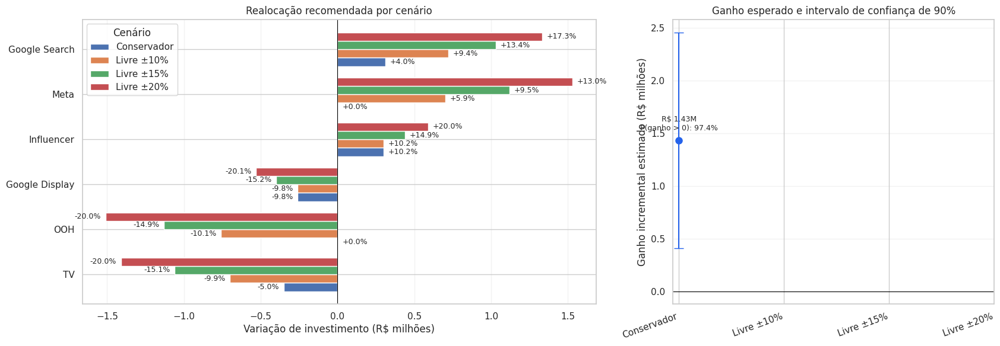

In [70]:
plot_optimization_comparison(
    allocation_comparison=allocation_comparison,
    gain_comparison=gain_comparison,
)